# Diplomatura en Ciencia de Datos, Inteligencia Artificial y sus Aplicaciones en Economía y Negocios (FCE–FaMAF, UNC) — Edición 2026
## Actividad Integradora Final · Base 10 (PaySim): detección de fraude en pagos móviles P2P
### Notebook 2 de 2 — Atributos, modelado, umbral económico y evaluación

**Grupo 21:** María Belén Silvano Ruata · Hector Eduardo Perez · Facundo Villena

**Entrada:** `datos/processed/base_curada_paysim.parquet` (Notebook 1). **Ejecución:** *Run All*; requiere además `scikit-learn`, `xgboost` y `joblib` y tarda entre 12 y 25 minutos con dos núcleos, según el equipo. Toda cifra se calcula en la celda que la imprime; solo las conclusiones citan cifras en texto fijo.

| Etapa de la consigna | Sección |
| :--- | :--- |
| Atributos ex ante y control de fuga | 2 |
| Partición temporal | 3 |
| Líneas de base | 4 |
| Métrica y búsqueda de hiperparámetros con validación cruzada temporal | 5 |
| Selección del modelo y sobreajuste | 6 |
| Calibración | 7 |
| Umbral económico y sensibilidad | 8 |
| Evaluación en un período posterior | 9 |
| Robustez: ablación, batería de ataques y entrenamiento con ataques | 10 |
| Explicabilidad, latencia, política operativa, ética y conclusiones | 11 a 15 |

## Sección 1. Configuración del entorno

In [1]:
# Configuración común: librerías, semilla, rutas portables, estilo gráfico y utilidades
import sys, time, platform, warnings, json
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
import scipy.stats as stats
import plotly
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from IPython.display import display, Markdown

SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)

# Raíz del proyecto: funciona tanto si el notebook se ejecuta desde notebooks/ como desde la raíz
_AQUI = Path.cwd().resolve()
BASE_DIR = _AQUI.parent if _AQUI.name == "notebooks" else _AQUI
OUTPUTS_DIR = BASE_DIR / "reports"
FIG_DIR, TAB_DIR, MOD_DIR = OUTPUTS_DIR / "figures", OUTPUTS_DIR / "tables", OUTPUTS_DIR / "models"
DATA_PROC_DIR = BASE_DIR / "data" / "processed"
for _p in (FIG_DIR, TAB_DIR, MOD_DIR, DATA_PROC_DIR):
    _p.mkdir(parents=True, exist_ok=True)

def ruta_rel(p):
    """Ruta relativa a la raíz del proyecto (evita exponer rutas locales del usuario)."""
    p = Path(p).resolve()
    try:
        return p.relative_to(BASE_DIR).as_posix()
    except ValueError:
        return p.name

# Paleta institucional (se conserva la identidad visual del trabajo)
COLOR_FRAUD, COLOR_LEGIT, COLOR_NEUTRAL, COLOR_ACCENT, COLOR_OK = "#B00020", "#1B365D", "#5C768D", "#D97706", "#0F766E"
pio.templates["mai"] = go.layout.Template(layout=go.Layout(
    font=dict(family="Arial, Helvetica, sans-serif", size=13, color="#1F2937"),
    title=dict(font=dict(size=16), x=0.0, xanchor="left"),
    plot_bgcolor="white", paper_bgcolor="white",
    xaxis=dict(showgrid=True, gridcolor="#E5E7EB", zeroline=False, linecolor="#9CA3AF"),
    yaxis=dict(showgrid=True, gridcolor="#E5E7EB", zeroline=False, linecolor="#9CA3AF"),
    legend=dict(bgcolor="rgba(255,255,255,0.8)"), hovermode="closest",
    separators=",.",  # convención rioplatense: coma decimal, punto de miles
))
pio.templates.default = "simple_white+mai"

# Renderizado: interactivo en Jupyter/VS Code; si kaleido está instalado se agrega una copia estática (PNG)
try:
    import kaleido  # noqa: F401
    _PNG_OK = True
except ImportError:
    _PNG_OK = False
pio.renderers.default = "plotly_mimetype+notebook_connected" + ("+png" if _PNG_OK else "")
if _PNG_OK:
    pio.renderers["png"].width, pio.renderers["png"].height = 1100, 520

def guardar_fig(fig, nombre):
    """Guarda la figura interactiva (HTML) y, si es posible, su versión estática (PNG) para el informe."""
    fig.write_html(FIG_DIR / f"{nombre}.html", include_plotlyjs="cdn")
    destino = f"{ruta_rel(FIG_DIR / nombre)}.html"
    if _PNG_OK:
        fig.write_image(FIG_DIR / f"{nombre}.png", width=1100, height=520, scale=2)
        destino += " y .png"
    print(f"Figura guardada en {destino}")

# Formato numérico rioplatense para los textos impresos
def f_int(x):
    return f"{int(round(x)):,}".replace(",", ".")

def f_num(x, d=2):
    return f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def f_pct(x, d=2):
    """x es una proporción (0-1)."""
    return f_num(100 * x, d) + "%"

def f_p(p):
    return "< 1e-300" if p == 0 else f"{p:.2e}"

def wilson(k, n, conf=0.95):
    """Intervalo de Wilson para una proporción binomial (apto para eventos raros)."""
    if n == 0:
        return (0.0, 0.0)
    z = stats.norm.ppf(1 - (1 - conf) / 2)
    p = k / n
    den = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / den
    semi = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return (max(0.0, centro - semi), min(1.0, centro + semi))

print(f"Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | "
      f"SciPy {scipy.__version__} | Plotly {plotly.__version__} | exportación PNG: {'sí' if _PNG_OK else 'no (instalar kaleido)'}")
print(f"Raíz del proyecto detectada: {BASE_DIR.name}/  |  semilla global: {SEED}")

import joblib, sklearn, xgboost as xgb
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_recall_curve, confusion_matrix)
print(f"scikit-learn {sklearn.__version__} | XGBoost {xgb.__version__} | joblib {joblib.__version__}")

Python 3.13.18 | pandas 3.0.5 | NumPy 2.5.3 | SciPy 1.18.1 | Plotly 7.1.0 | exportación PNG: sí
Raíz del proyecto detectada: Fraud/  |  semilla global: 42


scikit-learn 1.9.1 | XGBoost 3.4.1 | joblib 1.6.0


## Sección 2. Atributos ex ante
### 2.1 Historial causal del destino
Para cada par (destino, hora) se suman las operaciones y el monto recibidos en **[t − 168 h, t)**, sin la hora actual, que podría no haber ocurrido al autorizar. Se usan todos los tipos de operación; la celda 2.2 verifica la causalidad por fuerza bruta.

In [2]:
# 2.1 Carga y cálculo vectorizado del historial de 168 h por cuenta de destino
ruta_parquet = DATA_PROC_DIR / "base_curada_paysim.parquet"
if not ruta_parquet.exists():
    raise FileNotFoundError("No se encontró la base curada: ejecutar primero el Notebook 1.")
t0 = time.perf_counter()
df = pd.read_parquet(ruta_parquet)
assert len(df) == 6_362_620 and int(df["isFraud"].sum()) == 8_213, "La base curada no coincide con la del Notebook 1"
print(f"Base curada: {f_int(len(df))} filas, {df.shape[1]} columnas ({f_num(time.perf_counter() - t0, 1)} s)")

VENTANA_H = 168
es_riesgo = df["type"].isin(["TRANSFER", "CASH_OUT"]).to_numpy()
destinos_riesgo = pd.Index(df.loc[es_riesgo, "nameDest"].unique())
hist = (df.loc[df["nameDest"].isin(destinos_riesgo), ["nameDest", "step", "amount"]]
          .groupby(["nameDest", "step"], observed=True)
          .agg(ops=("amount", "size"), monto=("amount", "sum")).reset_index()
          .sort_values(["nameDest", "step"], kind="mergesort"))
hist["t"] = pd.to_timedelta(hist["step"].astype("int64"), unit="h")
roll = (hist.set_index("t").groupby("nameDest", sort=False)[["ops", "monto"]]
            .rolling(f"{VENTANA_H}h", closed="left").sum())
hist["ops_previas_168h"] = roll["ops"].fillna(0).to_numpy()
hist["monto_previo_168h"] = roll["monto"].fillna(0).to_numpy()
print(f"Historial calculado para {f_int(hist['nameDest'].nunique())} destinos y {f_int(len(hist))} pares (destino, hora) "
      f"en {f_num(time.perf_counter() - t0, 1)} s")

Base curada: 6.362.620 filas, 12 columnas (0,7 s)


Historial calculado para 509.565 destinos y 3.814.071 pares (destino, hora) en 17,0 s


In [3]:
# 2.2 Prueba de causalidad: recálculo por fuerza bruta de la ventana [t − 168, t) en 300 pares al azar
muestra = hist[hist["ops_previas_168h"] > 0].sample(150, random_state=SEED)
muestra = pd.concat([muestra, hist.sample(150, random_state=SEED + 1)])
eventos = df.loc[df["nameDest"].isin(muestra["nameDest"]), ["nameDest", "step", "amount"]]
errores = 0
for _, f in muestra.iterrows():
    e = eventos[(eventos["nameDest"] == f["nameDest"]) & (eventos["step"] >= f["step"] - VENTANA_H) & (eventos["step"] < f["step"])]
    errores += int(len(e) != f["ops_previas_168h"] or not np.isclose(e["amount"].sum(), f["monto_previo_168h"]))
assert errores == 0, f"{errores} discrepancias: la ventana no es causal"
print("Prueba superada: en los 300 pares, la ventana vectorizada coincide con el recálculo directo y nunca incluye la hora actual.")

Prueba superada: en los 300 pares, la ventana vectorizada coincide con el recálculo directo y nunca incluye la hora actual.


### 2.3 Catálogo de atributos
Doce atributos derivados del Notebook 1. Dos cambios respecto de la versión anterior: la razón monto/saldo pasa a escala logarítmica (en escala lineal llegaba a 92 millones y desestabilizaba a los modelos lineales) y el monto de 10.000.000 se reemplaza por el **tramo de 10 millones con saldo suficiente** (sección 3.2).

In [4]:
# 2.3 Construcción de los 12 atributos ex ante sobre TRANSFER y CASH_OUT
TOPE = 10_000_000.0
r = (df.loc[es_riesgo, ["step", "type", "amount", "oldbalanceOrg", "nameDest", "isFraud", "isFlaggedFraud"]]
       .merge(hist[["nameDest", "step", "ops_previas_168h", "monto_previo_168h"]], on=["nameDest", "step"], how="left")
       .reset_index(drop=True))
r[["ops_previas_168h", "monto_previo_168h"]] = r[["ops_previas_168h", "monto_previo_168h"]].fillna(0)
cm, cs = np.round(r["amount"] * 100).astype(np.int64), np.round(r["oldbalanceOrg"] * 100).astype(np.int64)
hora = (r["step"] % 24).to_numpy()

def construir_atributos(monto, saldo, tipo_transfer, hora, ops_prev, monto_prev):
    """Función única de atributos: se reutiliza en la simulación del atacante (sección 10)."""
    cmon, csal = np.round(monto * 100).astype(np.int64), np.round(saldo * 100).astype(np.int64)
    return pd.DataFrame({
        "es_transfer": tipo_transfer.astype(np.int8),
        "log_monto": np.log10(1 + monto),
        "log_saldo_orig": np.log10(1 + saldo),
        "emisor_sin_saldo": (csal == 0).astype(np.int8),
        "monto_excede_saldo": (cmon > csal).astype(np.int8),
        "log_ratio_monto_saldo": np.log10((1 + monto) / (1 + saldo)),
        "marca_vaciamiento": (cmon == csal).astype(np.int8),
        "tramo_10m_con_saldo": ((monto == TOPE) & (saldo >= TOPE)).astype(np.int8),
        "hora_sen": np.sin(2 * np.pi * hora / 24),
        "hora_cos": np.cos(2 * np.pi * hora / 24),
        "dest_ops_previas_log": np.log10(1 + ops_prev),
        "dest_monto_previo_log": np.log10(1 + monto_prev),
    })

X_all = construir_atributos(r["amount"].to_numpy(), r["oldbalanceOrg"].to_numpy(), (r["type"] == "TRANSFER").to_numpy(),
                            hora, r["ops_previas_168h"].to_numpy(), r["monto_previo_168h"].to_numpy())
FEATURES = list(X_all.columns)
y_all = r["isFraud"].to_numpy().astype(np.int8)
step_all = r["step"].to_numpy()
monto_all = r["amount"].to_numpy()
assert X_all.notna().all().all() and np.isfinite(X_all.to_numpy()).all()

catalogo = pd.DataFrame([
    ("es_transfer", "binaria", "TRANSFER = 1, CASH_OUT = 0", "Tipo de operación"),
    ("log_monto", "continua", "log10(1 + monto)", "Magnitud con escala atenuada"),
    ("log_saldo_orig", "continua", "log10(1 + saldo de origen previo)", "Capacidad de la cuenta"),
    ("emisor_sin_saldo", "binaria", "saldo de origen previo = 0", "Decisión 7 del Notebook 1"),
    ("monto_excede_saldo", "binaria", "monto > saldo de origen previo (al centavo)", "Decisión 8"),
    ("log_ratio_monto_saldo", "continua", "log10((1 + monto) / (1 + saldo))", "Vale 0 en un vaciamiento; acotada"),
    ("marca_vaciamiento", "binaria", "monto = saldo de origen previo (al centavo)", "Decisión 12"),
    ("tramo_10m_con_saldo", "binaria", "monto = 10.000.000 y saldo ≥ 10.000.000", "Decisión 5"),
    ("hora_sen / hora_cos", "continuas", "sen y cos de 2π·(step mod 24)/24", "Decisión 13"),
    ("dest_ops_previas_log", "continua", "log10(1 + operaciones recibidas por el destino en [t − 168 h, t))", "Decisión 14"),
    ("dest_monto_previo_log", "continua", "log10(1 + monto recibido por el destino en [t − 168 h, t))", "Decisión 14"),
], columns=["Atributo", "Tipo", "Definición", "Origen"])
with pd.option_context("display.max_colwidth", None):
    display(catalogo)
print(f"Matriz de atributos: {f_int(X_all.shape[0])} operaciones x {X_all.shape[1]} atributos, todos conocidos al autorizar. "
      "Excluidos por ser ex post: newbalanceOrig y newbalanceDest. Excluidos por ser identificadores: nameOrig y nameDest.")
del df, hist, roll

,Atributo,Tipo,Definición,Origen
0,es_transfer,binaria,"TRANSFER = 1, CASH_OUT = 0",Tipo de operación
1,log_monto,continua,log10(1 + monto),Magnitud con escala atenuada
2,log_saldo_orig,continua,log10(1 + saldo de origen previo),Capacidad de la cuenta
3,emisor_sin_saldo,binaria,saldo de origen previo = 0,Decisión 7 del Notebook 1
4,monto_excede_saldo,binaria,monto > saldo de origen previo (al centavo),Decisión 8
5,log_ratio_monto_saldo,continua,log10((1 + monto) / (1 + saldo)),Vale 0 en un vaciamiento; acotada
6,marca_vaciamiento,binaria,monto = saldo de origen previo (al centavo),Decisión 12
7,tramo_10m_con_saldo,binaria,monto = 10.000.000 y saldo ≥ 10.000.000,Decisión 5
8,hora_sen / hora_cos,continuas,sen y cos de 2π·(step mod 24)/24,Decisión 13
9,dest_ops_previas_log,continua,"log10(1 + operaciones recibidas por el destino en [t − 168 h, t))",Decisión 14


Matriz de atributos: 2.770.409 operaciones x 12 atributos, todos conocidos al autorizar. Excluidos por ser ex post: newbalanceOrig y newbalanceDest. Excluidos por ser identificadores: nameOrig y nameDest.


In [5]:
# 2.4 Deriva del historial: la ventana está truncada en los primeros 7 días
semana = np.minimum((step_all - 1) // 168 + 1, 5)
deriva = pd.DataFrame({"semana": semana, "con_historial": X_all["dest_ops_previas_log"].to_numpy() > 0, "fraude": y_all})
tabla_deriva = deriva.groupby(["semana", "fraude"])["con_historial"].mean().unstack() * 100
tabla_deriva.columns = ["% legítimas con historial", "% fraudes con historial"]
tabla_deriva.index = [f"Semana {s}" + (" (steps 673 a 743)" if s == 5 else "") for s in tabla_deriva.index]
display(tabla_deriva.round(1))
print(f"El truncamiento de la primera semana casi no se nota ({f_num(tabla_deriva.iloc[0, 0], 1)}% de legítimas con historial frente a "
      f"{f_num(tabla_deriva.iloc[1, 0], 1)}% en la segunda), porque muchas cuentas reciben operaciones a diario. La deriva relevante está en el "
      f"período de prueba: en las semanas 4 y 5 la proporción cae a {f_num(tabla_deriva.iloc[3, 0], 1)}% y {f_num(tabla_deriva.iloc[4, 0], 1)}%, "
      "por la caída del volumen legítimo. El atributo cambia de distribución entre entrenamiento y prueba; la sección 9 muestra si eso afecta el desempeño "
      "y la sección 6.3 mide el efecto de entrenar sin la primera semana.")

,% legítimas con historial,% fraudes con historial
Semana 1,83.1,37.0
Semana 2,85.6,36.1
Semana 3,84.6,33.9
Semana 4,42.0,15.3
Semana 5 (steps 673 a 743),21.9,8.4


El truncamiento de la primera semana casi no se nota (83,1% de legítimas con historial frente a 85,6% en la segunda), porque muchas cuentas reciben operaciones a diario. La deriva relevante está en el período de prueba: en las semanas 4 y 5 la proporción cae a 42,0% y 21,9%, por la caída del volumen legítimo. El atributo cambia de distribución entre entrenamiento y prueba; la sección 9 muestra si eso afecta el desempeño y la sección 6.3 mide el efecto de entrenar sin la primera semana.


## Sección 3. Partición cronológica
Entrenamiento: días 1–12 (steps 1–288). Validación: días 13–15 (289–360), para elegir hiperparámetros, modelo y umbral. Prueba: días 16–31 (361–743), **evaluación en un período posterior**. El modelo y sus hiperparámetros se eligieron sin mirarla. La excepción es el criterio para ubicar el umbral dentro del intervalo que la validación no distingue: se adoptó después de comparar el borde y el centro en prueba, y por eso la sección 8 informa los dos resultados. No se mezclan períodos, para no entrenar con operaciones futuras.

,Partición,Días,Steps,Operaciones,Fraudes,Monto defraudado (u.m.),Prevalencia (%),Operaciones por día
0,Entrenamiento,1 a 12,1 a 288,"1,729,766","3,279","4,395,229,478",0.190,"144,147"
1,Validación,13 a 15,289 a 360,"535,132",738,"1,088,013,135",0.138,"178,377"
2,Prueba,16 a 31,361 a 743,"505,511","4,196","6,573,172,815",0.830,"31,594"


La prevalencia pasa de 0,190% en entrenamiento a 0,830% en prueba: los fraudes diarios se mantienen y las operaciones diarias caen de 144.147 a 31.594. No es solo una prueba de estrés: con más fraude relativo la precisión mejora mecánicamente, por eso se reporta también la tasa de falsos positivos.


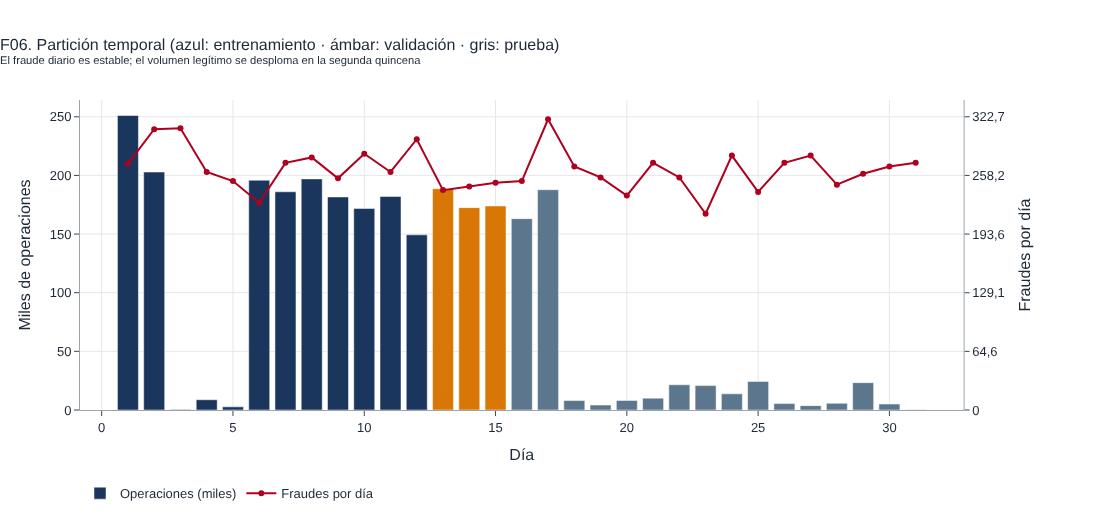

Figura guardada en outputs/figures/F06_particion_temporal.html y .png


In [6]:
# 3.1 Partición temporal
tr, va, te = step_all <= 288, (step_all > 288) & (step_all <= 360), step_all > 360
DIAS = {"Entrenamiento": 12, "Validación": 3, "Prueba": 16}
X_tr, X_va, X_te = X_all[tr], X_all[va], X_all[te]
y_tr, y_va, y_te = y_all[tr], y_all[va], y_all[te]
m_tr, m_va, m_te = monto_all[tr], monto_all[va], monto_all[te]

part = pd.DataFrame({
    "Partición": list(DIAS), "Días": ["1 a 12", "13 a 15", "16 a 31"], "Steps": ["1 a 288", "289 a 360", "361 a 743"],
    "Operaciones": [tr.sum(), va.sum(), te.sum()], "Fraudes": [y_tr.sum(), y_va.sum(), y_te.sum()],
    "Monto defraudado (u.m.)": [m_tr[y_tr == 1].sum(), m_va[y_va == 1].sum(), m_te[y_te == 1].sum()]})
part["Prevalencia (%)"] = part["Fraudes"] / part["Operaciones"] * 100
part["Operaciones por día"] = part["Operaciones"] / list(DIAS.values())
assert part["Fraudes"].sum() == 8_213
part.to_csv(TAB_DIR / "tabla_particion_temporal.csv", index=False)
display(part.style.format({"Operaciones": "{:,}", "Fraudes": "{:,}", "Monto defraudado (u.m.)": "{:,.0f}",
                           "Prevalencia (%)": "{:.3f}", "Operaciones por día": "{:,.0f}"}))
print(f"La prevalencia pasa de {f_num(part['Prevalencia (%)'][0], 3)}% en entrenamiento a {f_num(part['Prevalencia (%)'][2], 3)}% en prueba: "
      f"los fraudes diarios se mantienen y las operaciones diarias caen de {f_int(part['Operaciones por día'][0])} a {f_int(part['Operaciones por día'][2])}. "
      "No es solo una prueba de estrés: con más fraude relativo la precisión mejora mecánicamente, por eso se reporta también la tasa de falsos positivos.")

dia_all = (step_all - 1) // 24 + 1
pd_dia = pd.DataFrame({"dia": dia_all, "y": y_all}).groupby("dia")["y"].agg(["size", "sum"])
fig = make_subplots(specs=[[{"secondary_y": True}]])
colores = [COLOR_LEGIT if d <= 12 else COLOR_ACCENT if d <= 15 else COLOR_NEUTRAL for d in pd_dia.index]
fig.add_bar(x=pd_dia.index, y=pd_dia["size"] / 1e3, marker_color=colores, name="Operaciones (miles)")
fig.add_scatter(x=pd_dia.index, y=pd_dia["sum"], mode="lines+markers", name="Fraudes por día",
                line=dict(color=COLOR_FRAUD), secondary_y=True)
fig.update_layout(title="F06. Partición temporal (azul: entrenamiento · ámbar: validación · gris: prueba)<br>"
                        "<sup>El fraude diario es estable; el volumen legítimo se desploma en la segunda quincena</sup>",
                  height=470, margin=dict(t=100, b=90), legend=dict(orientation="h", y=-0.22))
fig.update_xaxes(title_text="Día"); fig.update_yaxes(title_text="Miles de operaciones", secondary_y=False)
fig.update_yaxes(title_text="Fraudes por día", secondary_y=True, showgrid=False, rangemode="tozero")
fig.show(); guardar_fig(fig, "F06_particion_temporal")

In [7]:
# 3.2 ¿Las firmas valen dentro del entrenamiento? (el diseño de atributos no debe depender del período de prueba)
filas = []
for nombre, mask in [("Entrenamiento", tr), ("Validación", va), ("Prueba", te)]:
    Xp, yp = X_all[mask], y_all[mask]
    filas.append({"Partición": nombre,
                  "Vaciamiento exacto: legítimas": int(Xp["marca_vaciamiento"][yp == 0].sum()),
                  "Vaciamiento exacto: % de fraudes": Xp["marca_vaciamiento"][yp == 1].mean() * 100,
                  "Tramo 10 M con saldo: legítimas": int(Xp["tramo_10m_con_saldo"][yp == 0].sum()),
                  "Monto = 10 M (aislado): legítimas": int((monto_all[mask][yp == 0] == TOPE).sum()),
                  "Monto = 10 M (aislado): fraudes": int((monto_all[mask][yp == 1] == TOPE).sum())})
firmas = pd.DataFrame(filas).set_index("Partición")
display(firmas.style.format({"Vaciamiento exacto: % de fraudes": "{:.2f}"}))
print("En entrenamiento ninguna legítima vacía la cuenta ni pide un tramo de 10 millones con saldo suficiente: las dos firmas, identificadas "
      "al explorar el mes completo, ya estaban presentes en los días 1 a 12.")
print(f"El monto aislado de 10.000.000 no tiene legítimas en entrenamiento pero sí {f_int(firmas.iloc[1, 3])} en validación y "
      f"{f_int(firmas.iloc[2, 3])} en prueba. Un modelo que lo use aprende 'monto 10 M = fraude' y falla cuando aparece la ráfaga legítima.")

,Vaciamiento exacto: legítimas,Vaciamiento exacto: % de fraudes,Tramo 10 M con saldo: legítimas,Monto = 10 M (aislado): legítimas,Monto = 10 M (aislado): fraudes
Partición,,,,,
Entrenamiento,0,97.96,0,0,72
Validación,0,98.78,0,2852,18
Prueba,0,97.55,0,68,197


En entrenamiento ninguna legítima vacía la cuenta ni pide un tramo de 10 millones con saldo suficiente: las dos firmas, identificadas al explorar el mes completo, ya estaban presentes en los días 1 a 12.
El monto aislado de 10.000.000 no tiene legítimas en entrenamiento pero sí 2.852 en validación y 68 en prueba. Un modelo que lo use aprende 'monto 10 M = fraude' y falla cuando aparece la ráfaga legítima.


In [8]:
# 3.3 Respuesta a la consulta sobre las métricas idénticas de logística, LDA y QDA en la versión anterior
X_viejo = X_all.drop(columns=["tramo_10m_con_saldo"]).assign(en_tope_10m=(monto_all == TOPE).astype(np.int8))
diag = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, solver="newton-cholesky")).fit(X_viejo[tr], y_tr)
p_diag = diag.predict_proba(X_viejo[va])[:, 1]
alerta = p_diag >= 0.5
fp_diag = alerta & (y_va == 0)
print(f"Con el atributo anterior (monto = 10 M aislado), la logística emite {f_int(alerta.sum())} alertas en validación con p ≥ 0,5: "
      f"{f_int((alerta & (y_va == 1)).sum())} fraudes y {f_int(fp_diag.sum())} legítimas.")
print(f"De esas legítimas, {f_pct((m_va[fp_diag] == TOPE).mean(), 1)} son transferencias de exactamente 10.000.000. "
      "Los tres modelos lineales coincidían en F1 y Brier porque marcaban el mismo bloque: todos los fraudes más la ráfaga legítima de 10 M. "
      "No eran predicciones copiadas sino el mismo error de diseño de atributos, que la nueva definición corrige.")
del X_viejo, diag, p_diag

Con el atributo anterior (monto = 10 M aislado), la logística emite 3.590 alertas en validación con p ≥ 0,5: 738 fraudes y 2.852 legítimas.
De esas legítimas, 100,0% son transferencias de exactamente 10.000.000. Los tres modelos lineales coincidían en F1 y Brier porque marcaban el mismo bloque: todos los fraudes más la ráfaga legítima de 10 M. No eran predicciones copiadas sino el mismo error de diseño de atributos, que la nueva definición corrige.


## Sección 4. Líneas de base
Tres alternativas simples: la **regla vigente** (`isFlaggedFraud`), **monto alto** (mayor o igual al percentil 99 de entrenamiento) y una **regla de firmas** (vaciamiento exacto o tramo de 10 millones con saldo). La última es la más exigente: si dos condiciones resuelven casi todo, el aporte del modelo está en la gestión del riesgo.

In [9]:
# 4.1 Definición de las líneas de base (parámetros estimados solo con entrenamiento)
P99_TR = float(np.quantile(m_tr, 0.99))
reglas = {
    "Regla vigente (isFlaggedFraud)": r["isFlaggedFraud"].to_numpy() == 1,
    "Monto ≥ P99 de entrenamiento": monto_all >= P99_TR,
    "Regla de firmas (vaciamiento o tramo 10 M)": (X_all["marca_vaciamiento"].to_numpy() == 1) | (X_all["tramo_10m_con_saldo"].to_numpy() == 1),
}
filas = []
for nombre, pred in reglas.items():
    for part_n, mask, yp in [("Validación", va, y_va)]:
        pr = pred[mask]; tp = int((pr & (yp == 1)).sum()); fp = int((pr & (yp == 0)).sum())
        filas.append({"Línea de base": nombre, "Alertas": int(pr.sum()), "Fraudes detectados": tp, "Falsos positivos": fp,
                      "Sensibilidad (%)": tp / yp.sum() * 100, "Precisión (%)": tp / pr.sum() * 100 if pr.sum() else np.nan})
print("Desempeño de las líneas de base en validación (días 13 a 15); la precisión no está definida cuando la regla no emite alertas.")
display(pd.DataFrame(filas).style.format({"Sensibilidad (%)": "{:.2f}", "Precisión (%)": "{:.2f}", "Alertas": "{:,}", "Falsos positivos": "{:,}"}, na_rep="—"))
print(f"Percentil 99 del monto en entrenamiento: {f_num(P99_TR)} u.m. La evaluación de las líneas de base en prueba se hace en la sección 9, "
      "junto con los modelos.")

Desempeño de las líneas de base en validación (días 13 a 15); la precisión no está definida cuando la regla no emite alertas.


,Línea de base,Alertas,Fraudes detectados,Falsos positivos,Sensibilidad (%),Precisión (%)
0,Regla vigente (isFlaggedFraud),0,0,0,0.00,—
1,Monto ≥ P99 de entrenamiento,"24,020",164,"23,856",22.22,0.68
2,Regla de firmas (vaciamiento o tramo 10 M),738,738,0,100.00,100.00


Percentil 99 del monto en entrenamiento: 1.817.543,18 u.m. La evaluación de las líneas de base en prueba se hace en la sección 9, junto con los modelos.


## Sección 5. Métrica y búsqueda de hiperparámetros
**Métrica.** PR-AUC (*average precision*): con un fraude cada 337 operaciones la ROC-AUC sigue alta aun con miles de falsas alarmas, mientras que la PR-AUC mide la calidad de la lista de alertas. La métrica de negocio es el ahorro neto (sección 8).

**Puntajes.** Se usa la escala *log-odds* cuando existe, porque las probabilidades se saturan en 1 y generan empates.

**Validación cruzada temporal.** Tres pliegues con origen móvil dentro de los días 1–15 (entrenar 1–6 y validar 7–9; 1–9 y 10–12; 1–12 y 13–15), con el escalado ajustado dentro de cada pliegue.

In [10]:
# 5.1 Pliegues, familias de modelos y grillas
PLIEGUES = [("Pliegue 1", 144, 216), ("Pliegue 2", 216, 288), ("Pliegue 3", 288, 360)]  # (fin entrenamiento, fin validación)

def puntaje(modelo, X):
    """Puntaje de ordenamiento: log-odds si el modelo lo provee; si no, probabilidad."""
    if isinstance(modelo, xgb.XGBClassifier):
        return modelo.predict(X, output_margin=True)
    if hasattr(modelo, "decision_function"):
        return modelo.decision_function(X)
    return modelo.predict_proba(X)[:, 1]

def prob(modelo, X):
    return modelo.predict_proba(X)[:, 1]

FAMILIAS = {
    "Regresión logística": (lambda C, cw: make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight=cw, solver="newton-cholesky", max_iter=1000)),
                            [dict(C=C, cw=cw) for cw in (None, "balanced") for C in (0.01, 0.1, 1.0, 10.0, 100.0)]),
    "LDA": (lambda solver, shrinkage: make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver=solver, shrinkage=shrinkage)),
            [dict(solver="svd", shrinkage=None), dict(solver="lsqr", shrinkage="auto")]),
    "QDA": (lambda reg: make_pipeline(StandardScaler(), QuadraticDiscriminantAnalysis(reg_param=reg)),
            [dict(reg=v) for v in (0.01, 0.1, 0.5)]),
    "Árbol de decisión (CART)": (lambda depth: DecisionTreeClassifier(max_depth=depth, min_samples_leaf=50, random_state=SEED),
                                 [dict(depth=d) for d in (4, 6, 8, 12)]),
    "Random Forest": (lambda depth, leaf: RandomForestClassifier(n_estimators=100, max_depth=depth, min_samples_leaf=leaf, max_samples=0.25,
                                                                 max_features="sqrt", n_jobs=-1, random_state=SEED),
                      [dict(depth=d, leaf=l) for d in (8, 12) for l in (20, 100)]),
    "XGBoost": (lambda depth, lr: xgb.XGBClassifier(n_estimators=300, max_depth=depth, learning_rate=lr, subsample=0.8, colsample_bytree=0.8,
                                                    tree_method="hist", n_jobs=-1, random_state=SEED, eval_metric="aucpr"),
                [dict(depth=d, lr=l) for d in (3, 5) for l in (0.05, 0.1)]),
}
CORTO = {"Regresión logística": "Logística", "LDA": "LDA", "QDA": "QDA", "Árbol de decisión (CART)": "CART", "Random Forest": "Random Forest", "XGBoost": "XGBoost"}
COMPLEJIDAD = {f: i for i, f in enumerate(FAMILIAS, start=1)}  # orden de simplicidad e interpretabilidad declarado de antemano
# Dentro de cada familia, clave de complejidad para desempatar con la regla de un error estándar (menor = más simple)
CLAVE_HP = {
    "Regresión logística": lambda hp: (hp["cw"] is not None, hp["C"]),      # sin reponderar (conserva la calibración) y más regularizada
    "LDA": lambda hp: (hp["solver"] != "svd",),
    "QDA": lambda hp: (-hp["reg"],),                                         # más regularización = más simple
    "Árbol de decisión (CART)": lambda hp: (hp["depth"],),
    "Random Forest": lambda hp: (hp["depth"], -hp["leaf"]),
    "XGBoost": lambda hp: (hp["depth"], hp["lr"]),
}
print("Familias (de más simple a más compleja): " + " < ".join(FAMILIAS))
print(f"Configuraciones a evaluar: {sum(len(g) for _, g in FAMILIAS.values())} x {len(PLIEGUES)} pliegues")

Familias (de más simple a más compleja): Regresión logística < LDA < QDA < Árbol de decisión (CART) < Random Forest < XGBoost
Configuraciones a evaluar: 27 x 3 pliegues


In [11]:
# 5.2 Validación cruzada temporal (la ejecución más larga del notebook)
cv_filas, scores_val = [], {}
t_cv = time.perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=UserWarning)   # avisos de colinealidad de QDA con atributos binarios
    for fam, (constructor, grilla) in FAMILIAS.items():
        for hp in grilla:
            aps, t0 = [], time.perf_counter()
            for nombre, fin_tr, fin_va in PLIEGUES:
                mtr = step_all <= fin_tr; mva = (step_all > fin_tr) & (step_all <= fin_va)
                modelo = constructor(**hp).fit(X_all[mtr], y_all[mtr])
                s = puntaje(modelo, X_all[mva])
                aps.append(average_precision_score(y_all[mva], s))
            cv_filas.append({"Familia": fam, "Hiperparámetros": ", ".join(f"{k}={v}" for k, v in hp.items()),
                             **{f"PR-AUC {p[0]}": a for p, a in zip(PLIEGUES, aps)},
                             "PR-AUC media": np.mean(aps), "Desvío": np.std(aps, ddof=1), "Segundos": time.perf_counter() - t0,
                             "_hp": hp})
cv = pd.DataFrame(cv_filas)
cv["Error estándar"] = cv["Desvío"] / np.sqrt(len(PLIEGUES))
cv.drop(columns="_hp").to_csv(TAB_DIR / "tabla_validacion_cruzada_temporal.csv", index=False)
print(f"Validación cruzada completa en {f_num((time.perf_counter() - t_cv) / 60, 1)} minutos.")
display(cv.drop(columns=["_hp"]).style.format({c: "{:.5f}" for c in cv.columns if c.startswith("PR-AUC") or c in ("Desvío", "Error estándar")} | {"Segundos": "{:.0f}"}))

Validación cruzada completa en 7,5 minutos.


,Familia,Hiperparámetros,PR-AUC Pliegue 1,PR-AUC Pliegue 2,PR-AUC Pliegue 3,PR-AUC media,Desvío,Segundos,Error estándar
0,Regresión logística,"C=0.01, cw=None",0.99643,0.99771,1.00000,0.99805,0.00181,4,0.00104
1,Regresión logística,"C=0.1, cw=None",0.99651,0.99770,1.00000,0.99807,0.00177,5,0.00102
2,Regresión logística,"C=1.0, cw=None",0.99652,0.99770,1.00000,0.99807,0.00177,5,0.00102
3,Regresión logística,"C=10.0, cw=None",0.99652,0.99770,1.00000,0.99807,0.00177,5,0.00102
4,Regresión logística,"C=100.0, cw=None",0.99652,0.99770,1.00000,0.99807,0.00177,5,0.00102
5,Regresión logística,"C=0.01, cw=balanced",0.99655,0.99768,1.00000,0.99808,0.00176,7,0.00101
6,Regresión logística,"C=0.1, cw=balanced",0.99656,0.99768,1.00000,0.99808,0.00176,5,0.00101
7,Regresión logística,"C=1.0, cw=balanced",0.99656,0.99768,1.00000,0.99808,0.00176,5,0.00101
8,Regresión logística,"C=10.0, cw=balanced",0.99656,0.99768,1.00000,0.99808,0.00176,6,0.00101
9,Regresión logística,"C=100.0, cw=balanced",0.99656,0.99768,1.00000,0.99808,0.00176,5,0.00101


,Familia,Hiperparámetros,PR-AUC media,Desvío,Error estándar
0,Regresión logística,"C=0.01, cw=None",0.99805,0.00181,0.00104
1,LDA,"solver=svd, shrinkage=None",0.99799,0.00186,0.00108
2,QDA,reg=0.5,0.99799,0.00187,0.00108
3,Árbol de decisión (CART),depth=4,0.99783,0.00170,0.00098
4,Random Forest,"depth=8, leaf=100",0.99798,0.00187,0.00108
5,XGBoost,"depth=3, lr=0.05",0.99803,0.00181,0.00105


Dentro de cada familia la PR-AUC media cambia como máximo 0,00006 entre configuraciones, y entre familias la diferencia de las elegidas es 0,00021, del orden de un error estándar (0,00105): los hiperparámetros casi no importan en este problema.


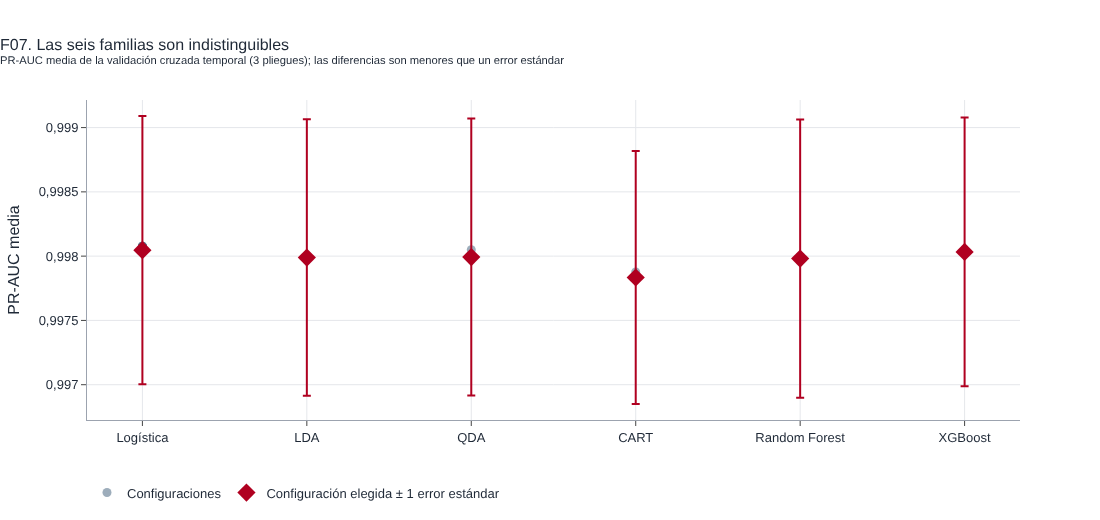

Figura guardada en outputs/figures/F07_validacion_cruzada.html y .png


In [12]:
# 5.3 Mejor configuración por familia y figura F07
def elegir_en_familia(g):
    top = g.loc[g["PR-AUC media"].idxmax()]
    dentro = g[g["PR-AUC media"] >= top["PR-AUC media"] - top["Error estándar"]]
    return dentro.loc[min(dentro.index, key=lambda i: CLAVE_HP[g.loc[i, "Familia"]](g.loc[i, "_hp"]))]
mejor = pd.DataFrame([elegir_en_familia(g) for _, g in cv.groupby("Familia")])
mejor["orden"] = mejor["Familia"].map(COMPLEJIDAD)
mejor = mejor.sort_values("orden").reset_index(drop=True)
display(mejor[["Familia", "Hiperparámetros", "PR-AUC media", "Desvío", "Error estándar"]].style.format(
    {"PR-AUC media": "{:.5f}", "Desvío": "{:.5f}", "Error estándar": "{:.5f}"}))
rango = cv.groupby("Familia")["PR-AUC media"].agg(["min", "max"])
print(f"Dentro de cada familia la PR-AUC media cambia como máximo {f_num((rango['max'] - rango['min']).max(), 5)} entre configuraciones, "
      f"y entre familias la diferencia de las elegidas es {f_num(mejor['PR-AUC media'].max() - mejor['PR-AUC media'].min(), 5)}, "
      f"del orden de un error estándar ({f_num(mejor['Error estándar'].mean(), 5)}): los hiperparámetros casi no importan en este problema.")

fig = go.Figure()
for fam in FAMILIAS:
    sub = cv[cv["Familia"] == fam]
    fig.add_scatter(x=[CORTO[fam]] * len(sub), y=sub["PR-AUC media"], mode="markers", marker=dict(size=9, color=COLOR_NEUTRAL, opacity=0.6),
                    name="Configuraciones", showlegend=(fam == "Regresión logística"), customdata=sub[["Hiperparámetros"]],
                    hovertemplate="%{x}<br>%{customdata[0]}<br>PR-AUC media %{y:.5f}<extra></extra>")
fig.add_scatter(x=mejor["Familia"].map(CORTO), y=mejor["PR-AUC media"], mode="markers", marker=dict(size=14, color=COLOR_FRAUD, symbol="diamond"),
                error_y=dict(type="data", array=mejor["Error estándar"]), name="Configuración elegida ± 1 error estándar")
fig.update_layout(title="F07. Las seis familias son indistinguibles<br><sup>PR-AUC media de la validación cruzada temporal (3 pliegues); las diferencias son menores que un error estándar</sup>",
                  yaxis_title="PR-AUC media", height=480, margin=dict(t=100, b=90), legend=dict(orientation="h", y=-0.18))
fig.show(); guardar_fig(fig, "F07_validacion_cruzada")

## Sección 6. Selección y sobreajuste
### 6.1 Regla de selección declarada de antemano
**Regla de un error estándar** (Breiman et al.): dentro de cada familia y entre familias, entre las opciones que no quedan por debajo de la mejor menos un error estándar, se elige la más simple (orden: logística, LDA, QDA, CART, Random Forest, XGBoost). Si el desempeño empata, deciden simplicidad, explicabilidad y latencia. El **retador** es el mejor ensamble de árboles, que aporta otro sesgo inductivo; LDA y QDA se descartan porque sus supuestos gaussianos no se cumplen con atributos binarios.

In [13]:
# 6.1 Aplicación de la regla y entrenamiento final de cada familia con días 1 a 12
best_row = mejor.loc[mejor["PR-AUC media"].idxmax()]
cota = best_row["PR-AUC media"] - best_row["Error estándar"]
candidatas = mejor[mejor["PR-AUC media"] >= cota]
CAMPEON = candidatas.sort_values("orden").iloc[0]["Familia"]
ENSAMBLES = ["Random Forest", "XGBoost"]
RETADOR = mejor[mejor["Familia"].isin(ENSAMBLES) & (mejor["Familia"] != CAMPEON)].sort_values("PR-AUC media", ascending=False).iloc[0]["Familia"]
print(f"Mejor PR-AUC media: {best_row['Familia']} ({f_num(best_row['PR-AUC media'], 5)}; error estándar {f_num(best_row['Error estándar'], 5)}). "
      f"Cota de la regla: {f_num(cota, 5)}.")
print(f"Familias dentro de la cota: {', '.join(candidatas['Familia'])}.")
print(f"Modelo campeón: {CAMPEON} ({mejor.set_index('Familia').loc[CAMPEON, 'Hiperparámetros']}). "
      f"Retador en modo sombra: {RETADOR} ({mejor.set_index('Familia').loc[RETADOR, 'Hiperparámetros']}).")

modelos, s_tr, s_va, s_te, p_tr, p_va, p_te = {}, {}, {}, {}, {}, {}, {}
t0 = time.perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=UserWarning)
    for _, f in mejor.iterrows():
        fam = f["Familia"]
        m = FAMILIAS[fam][0](**f["_hp"]).fit(X_tr, y_tr)
        modelos[fam] = m
        s_tr[fam], s_va[fam], s_te[fam] = puntaje(m, X_tr), puntaje(m, X_va), puntaje(m, X_te)
        p_tr[fam], p_va[fam], p_te[fam] = prob(m, X_tr), prob(m, X_va), prob(m, X_te)
print(f"Seis modelos finales entrenados con días 1 a 12 en {f_num(time.perf_counter() - t0, 0)} s.")

# Tabla de hiperparámetros para reproducir cada modelo final
FIJOS = {"Regresión logística": "solver='newton-cholesky', max_iter=1000; escalado estándar previo",
         "LDA": "escalado estándar previo", "QDA": "escalado estándar previo",
         "Árbol de decisión (CART)": "min_samples_leaf=50, random_state=42",
         "Random Forest": "n_estimators=100, max_samples=0.25, max_features='sqrt', random_state=42",
         "XGBoost": "n_estimators=300, subsample=0.8, colsample_bytree=0.8, tree_method='hist', random_state=42"}
GRILLA = {fam: "; ".join(", ".join(f"{k}={v}" for k, v in hp.items()) for hp in grilla) for fam, (_, grilla) in FAMILIAS.items()}
hiper = pd.DataFrame({"Modelo": mejor["Familia"],
                      "Rol": mejor["Familia"].map(lambda f: "Campeón" if f == CAMPEON else "Retador" if f == RETADOR else ""),
                      "Hiperparámetros elegidos": mejor["Hiperparámetros"],
                      "Hiperparámetros fijos": mejor["Familia"].map(FIJOS),
                      "Grilla explorada": mejor["Familia"].map(GRILLA),
                      "PR-AUC media (CV)": mejor["PR-AUC media"]})
hiper.to_csv(TAB_DIR / "tabla_hiperparametros_modelos.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(hiper.style.format({"PR-AUC media (CV)": "{:.5f}"}))
print("Notación: C = inversa de la regularización L2; cw = class_weight; reg = reg_param de QDA; depth = profundidad máxima; "
      "leaf = min_samples_leaf; lr = tasa de aprendizaje.")

Mejor PR-AUC media: Regresión logística (0,99805; error estándar 0,00104). Cota de la regla: 0,99700.
Familias dentro de la cota: Regresión logística, LDA, QDA, Árbol de decisión (CART), Random Forest, XGBoost.
Modelo campeón: Regresión logística (C=0.01, cw=None). Retador en modo sombra: XGBoost (depth=3, lr=0.05).


Seis modelos finales entrenados con días 1 a 12 en 61 s.


,Modelo,Rol,Hiperparámetros elegidos,Hiperparámetros fijos,Grilla explorada,PR-AUC media (CV)
0,Regresión logística,Campeón,"C=0.01, cw=None","solver='newton-cholesky', max_iter=1000; escalado estándar previo","C=0.01, cw=None; C=0.1, cw=None; C=1.0, cw=None; C=10.0, cw=None; C=100.0, cw=None; C=0.01, cw=balanced; C=0.1, cw=balanced; C=1.0, cw=balanced; C=10.0, cw=balanced; C=100.0, cw=balanced",0.99805
1,LDA,,"solver=svd, shrinkage=None",escalado estándar previo,"solver=svd, shrinkage=None; solver=lsqr, shrinkage=auto",0.99799
2,QDA,,reg=0.5,escalado estándar previo,reg=0.01; reg=0.1; reg=0.5,0.99799
3,Árbol de decisión (CART),,depth=4,"min_samples_leaf=50, random_state=42",depth=4; depth=6; depth=8; depth=12,0.99783
4,Random Forest,,"depth=8, leaf=100","n_estimators=100, max_samples=0.25, max_features='sqrt', random_state=42","depth=8, leaf=20; depth=8, leaf=100; depth=12, leaf=20; depth=12, leaf=100",0.99798
5,XGBoost,Retador,"depth=3, lr=0.05","n_estimators=300, subsample=0.8, colsample_bytree=0.8, tree_method='hist', random_state=42","depth=3, lr=0.05; depth=3, lr=0.1; depth=5, lr=0.05; depth=5, lr=0.1",0.99803


Notación: C = inversa de la regularización L2; cw = class_weight; reg = reg_param de QDA; depth = profundidad máxima; leaf = min_samples_leaf; lr = tasa de aprendizaje.


,Modelo,Rol,PR-AUC entrenamiento,PR-AUC validación,Brecha entrenamiento − validación (%),Sobreajuste (brecha > 5%),ROC-AUC validación,Brier validación
0,Regresión logística,Campeón,0.99176,1.00000,-0.83,No,1.00000,4.03e-09
1,LDA,,0.99118,1.00000,-0.89,No,1.00000,0.00e+00
2,QDA,,0.99093,1.00000,-0.92,No,1.00000,1.20e-53
3,Árbol de decisión (CART),,0.99084,0.99963,-0.89,No,1.00000,2.36e-05
4,Random Forest,,0.99207,1.00000,-0.80,No,1.00000,7.31e-05
5,XGBoost,Retador,0.99477,1.00000,-0.53,No,1.00000,1.64e-08


Modelos con brecha mayor a 5% entre entrenamiento y validación: 0 (ninguno).
Las brechas son negativas: todos los modelos rinden algo mejor en validación que en entrenamiento. La causa es la composición de los períodos: en validación el 100,00% de los fraudes presenta alguna firma, frente al 99,05% en entrenamiento, de modo que los casos de validación son, en promedio, más fáciles. No hay indicios de sobreajuste. La comparación con el período de prueba se hace recién en la sección 9.5, cuando el modelo y el umbral ya están fijados.


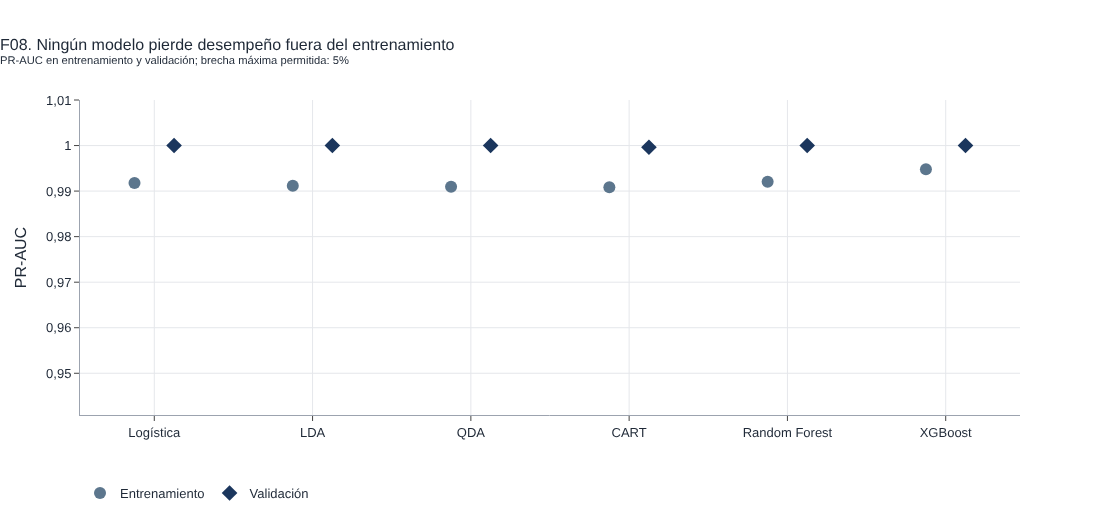

Figura guardada en outputs/figures/F08_comparacion_modelos.html y .png


In [14]:
# 6.2 Comparación entrenamiento / validación y criterio de sobreajuste (la prueba no se mira hasta la sección 9)
REGLA_GAP = 5.0
filas = []
for fam in modelos:
    a_tr, a_va = (average_precision_score(y, s[fam]) for y, s in [(y_tr, s_tr), (y_va, s_va)])
    gap = (a_tr - a_va) / a_tr * 100
    filas.append({"Modelo": fam, "Rol": "Campeón" if fam == CAMPEON else "Retador" if fam == RETADOR else "",
                  "PR-AUC entrenamiento": a_tr, "PR-AUC validación": a_va,
                  "Brecha entrenamiento − validación (%)": gap,
                  "Sobreajuste (brecha > 5%)": "Sí" if gap > REGLA_GAP else "No",
                  "ROC-AUC validación": roc_auc_score(y_va, s_va[fam]), "Brier validación": brier_score_loss(y_va, p_va[fam])})
comp = pd.DataFrame(filas)
comp.to_csv(TAB_DIR / "tabla_comparacion_modelos.csv", index=False)
display(comp.style.format({c: "{:.5f}" for c in comp.columns if "PR-AUC" in c or "ROC" in c} |
                          {"Brecha entrenamiento − validación (%)": "{:+.2f}", "Brier validación": "{:.2e}"}))
n_sobre = (comp["Sobreajuste (brecha > 5%)"] == "Sí").sum()
print(f"Modelos con brecha mayor a {f_num(REGLA_GAP, 0)}% entre entrenamiento y validación: {n_sobre} "
      f"({', '.join(comp.loc[comp['Sobreajuste (brecha > 5%)'] == 'Sí', 'Modelo']) or 'ninguno'}).")
firma = lambda Xp, yp: ((Xp["marca_vaciamiento"] == 1) | (Xp["tramo_10m_con_saldo"] == 1))[yp == 1].mean()
print(f"Las brechas son negativas: todos los modelos rinden algo mejor en validación que en entrenamiento. La causa es la composición de los períodos: "
      f"en validación el {f_pct(firma(X_va, y_va))} de los fraudes presenta alguna firma, frente al {f_pct(firma(X_tr, y_tr))} en entrenamiento, de modo que "
      "los casos de validación son, en promedio, más fáciles. No hay indicios de sobreajuste. La comparación con el período de prueba se hace recién "
      "en la sección 9.5, cuando el modelo y el umbral ya están fijados.")

fig = go.Figure()
xpos = np.arange(len(comp))
for k_, (col, nombre, color, simb) in enumerate([("PR-AUC entrenamiento", "Entrenamiento", COLOR_NEUTRAL, "circle"), ("PR-AUC validación", "Validación", COLOR_LEGIT, "diamond")]):
    fig.add_scatter(x=xpos + (k_ - 0.5) * 0.25, y=comp[col], name=nombre, mode="markers", marker=dict(color=color, size=12, symbol=simb),
                    customdata=comp[["Modelo"]], hovertemplate="%{customdata[0]}<br>" + nombre + ": %{y:.5f}<extra></extra>")
fig.update_xaxes(tickmode="array", tickvals=xpos, ticktext=comp["Modelo"].map(CORTO))
fig.update_layout(title="F08. Ningún modelo pierde desempeño fuera del entrenamiento<br><sup>PR-AUC en entrenamiento y validación; brecha máxima permitida: 5%</sup>",
                  margin=dict(t=100, b=90), yaxis_title="PR-AUC",
                  yaxis_range=[max(0, comp[["PR-AUC entrenamiento", "PR-AUC validación"]].min().min() - 0.05), 1.01], height=460,
                  legend=dict(orientation="h", y=-0.2))
fig.show(); guardar_fig(fig, "F08_comparacion_modelos")

In [15]:
# 6.3 Sensibilidad a la deriva del historial: campeón entrenado sin la primera semana (steps 169 a 288)
fam = CAMPEON
hp = mejor.set_index("Familia").loc[fam, "_hp"]
sin_sem1 = (step_all > 168) & (step_all <= 288)
m_alt = FAMILIAS[fam][0](**hp).fit(X_all[sin_sem1], y_all[sin_sem1])
ap_alt, ap_base = average_precision_score(y_va, puntaje(m_alt, X_va)), average_precision_score(y_va, s_va[fam])
print(f"{fam}: PR-AUC de validación {f_num(ap_base, 5)} entrenando con días 1 a 12 y {f_num(ap_alt, 5)} entrenando con días 8 a 12. "
      f"Diferencia: {f_num(ap_alt - ap_base, 5)}. " + ("La deriva de la primera semana no altera las conclusiones."
                                                        if abs(ap_alt - ap_base) < 0.01 else "La deriva tiene un efecto apreciable y se reporta como limitación."))

Regresión logística: PR-AUC de validación 1,00000 entrenando con días 1 a 12 y 1,00000 entrenando con días 8 a 12. Diferencia: 0,00000. La deriva de la primera semana no altera las conclusiones.


## Sección 7. Calibración
Una probabilidad está calibrada si, entre las operaciones con 0,8, cerca del 80% son fraude. No cambia el orden ni la PR-AUC, pero importa al comunicar el puntaje. Se compara el Brier con el de predecir siempre la prevalencia y se grafica la curva de confiabilidad. Con clases casi separadas, las probabilidades se concentran cerca de 0 y de 1: un Brier casi nulo refleja esa separación y dice poco sobre las probabilidades intermedias, que casi no se observan.

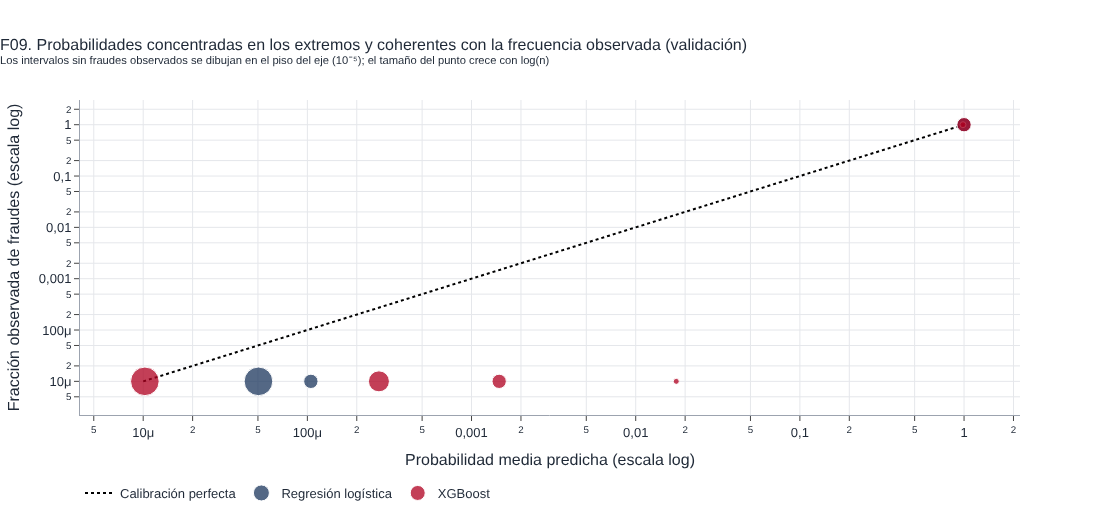

Figura guardada en outputs/figures/F09_calibracion.html y .png


,Modelo,Brier,Brier de referencia,Brier skill score,Probabilidad media predicha,Prevalencia observada
0,Regresión logística,4.028e-09,1.377e-03,+1.0000,0.00143,0.00138
1,XGBoost,1.642e-08,1.377e-03,+1.0000,0.00140,0.00138


Regresión logística: Brier 4.03e-09 frente a 1.38e-03 de referencia (mejor que la referencia; skill score 1,000). Probabilidad media predicha 0,143% frente a una prevalencia de 0,138%.
XGBoost: Brier 1.64e-08 frente a 1.38e-03 de referencia (mejor que la referencia; skill score 1,000). Probabilidad media predicha 0,140% frente a una prevalencia de 0,138%.


In [16]:
# 7.1 Brier, Brier de referencia y curva de confiabilidad en validación
prev_va = y_va.mean()
brier_ref = brier_score_loss(y_va, np.full(len(y_va), prev_va))
BORDES = np.array([0, 1e-4, 1e-3, 1e-2, 0.1, 0.5, 0.9, 0.99, 1 + 1e-12])
cal_filas = []
fig = go.Figure()
fig.add_scatter(x=[1e-5, 1], y=[1e-5, 1], mode="lines", line=dict(color="black", dash="dot"), name="Calibración perfecta")
for fam, color in [(CAMPEON, COLOR_LEGIT), (RETADOR, COLOR_FRAUD)]:
    pv = p_va[fam]
    idx = np.digitize(pv, BORDES) - 1
    g = pd.DataFrame({"bin": idx, "p": pv, "y": y_va}).groupby("bin").agg(n=("y", "size"), pred=("p", "mean"), obs=("y", "mean"))
    fig.add_scatter(x=g["pred"].clip(lower=1e-5), y=g["obs"].clip(lower=1e-5), mode="markers", name=fam,
                    marker=dict(color=color, size=np.clip(np.log10(g["n"] + 1) * 5, 6, 30), opacity=0.75, line=dict(width=1, color="white")),
                    customdata=g[["n"]], hovertemplate="predicha %{x:.4f}<br>observada %{y:.4f}<br>n = %{customdata[0]:,}<extra></extra>")
    b = brier_score_loss(y_va, pv)
    cal_filas.append({"Modelo": fam, "Brier": b, "Brier de referencia": brier_ref, "Brier skill score": 1 - b / brier_ref,
                      "Probabilidad media predicha": pv.mean(), "Prevalencia observada": prev_va})
fig.update_xaxes(type="log", title_text="Probabilidad media predicha (escala log)")
fig.update_yaxes(type="log", title_text="Fracción observada de fraudes (escala log)")
fig.update_layout(title="F09. Probabilidades concentradas en los extremos y coherentes con la frecuencia observada (validación)<br>"
                        "<sup>Los intervalos sin fraudes observados se dibujan en el piso del eje (10⁻⁵); el tamaño del punto crece con log(n)</sup>",
                  height=500, margin=dict(t=100, b=90), legend=dict(orientation="h", y=-0.2))
fig.show(); guardar_fig(fig, "F09_calibracion")
cal = pd.DataFrame(cal_filas)
display(cal.style.format({c: "{:.3e}" for c in ("Brier", "Brier de referencia")} | {"Brier skill score": "{:+.4f}",
                         "Probabilidad media predicha": "{:.5f}", "Prevalencia observada": "{:.5f}"}))
for _, f in cal.iterrows():
    juicio = "mejor que la referencia" if f["Brier skill score"] > 0 else "peor que la referencia"
    print(f"{f['Modelo']}: Brier {f['Brier']:.2e} frente a {f['Brier de referencia']:.2e} de referencia ({juicio}; skill score {f_num(f['Brier skill score'], 3)}). "
          f"Probabilidad media predicha {f_pct(f['Probabilidad media predicha'], 3)} frente a una prevalencia de {f_pct(f['Prevalencia observada'], 3)}.")

## Sección 8. Umbral económico y sensibilidad
$$\text{Ahorro}(u) = \sum_{i \in TP(u)} \text{monto}_i \;-\; C_{rev}\,\big(TP(u) + FP(u)\big) \;-\; C_{fric}\,FP(u)$$

$C_{rev}$ = 1.500 u.m. por alerta y $C_{fric}$ = 8.500 u.m. por cliente honesto retenido (supuestos), con un máximo de 1.000 alertas diarias. La función se evalúa en **todos** los umbrales que produce el modelo y se toma el punto medio de la franja factible que alcanza al menos el 99,9% del ahorro máximo de validación. Un umbral es factible si **ningún día** de validación supera el cupo; el promedio diario se muestra solo como descripción. El mismo criterio se aplica a todos los modelos y variantes del notebook. En prueba el umbral no cambia y cada día se atienden las alertas en el orden del archivo hasta completar el cupo (supuesto: PaySim registra la hora, no el minuto). Simplificación: la fricción no depende del monto.

,Modelo,Umbral (puntaje),Umbral (probabilidad),"Franja 99,9%: umbral mín.","Franja 99,9%: umbral máx.",Alertas/día (promedio),Alertas/día (máximo),Sensibilidad (%),Precisión (%),Ahorro (% del monto defraudado)
0,Regresión logística,-1.4559,0.189088,-9.1484,6.2366,246.0,250,100.00,100.00,99.898
1,XGBoost,-1.3155,0.211576,-6.2457,3.6148,246.0,250,100.00,100.00,99.898


Regresión logística: el ahorro alcanza al menos el 99,9% del máximo para cualquier umbral de puntaje entre -9,148 y 6,237; se adopta el punto medio, -1,456 (probabilidad 0,1891). Ningún día de validación supera el cupo (máximo: 250 alertas).
XGBoost: el ahorro alcanza al menos el 99,9% del máximo para cualquier umbral de puntaje entre -6,246 y 3,615; se adopta el punto medio, -1,315 (probabilidad 0,2116). Ningún día de validación supera el cupo (máximo: 250 alertas).
Bordes de la franja del campeón. Superior (6,237): es el puntaje del fraude de validación con menor puntaje (6,237); un umbral apenas mayor ya deja pasar un fraude. Inferior (-9,148): por debajo de la legítima de mayor puntaje (-8,954) la tolerancia del 0,1% admite retener a 108 clientes honestos.
Entre -8,954 y 6,237 todos los umbrales producen exactamente las mismas alertas en validación (738 fraudes y ninguna legítima): la validación no puede ordenarlos. Elegir uno es un criterio de extrapolación, no una optimización.
P

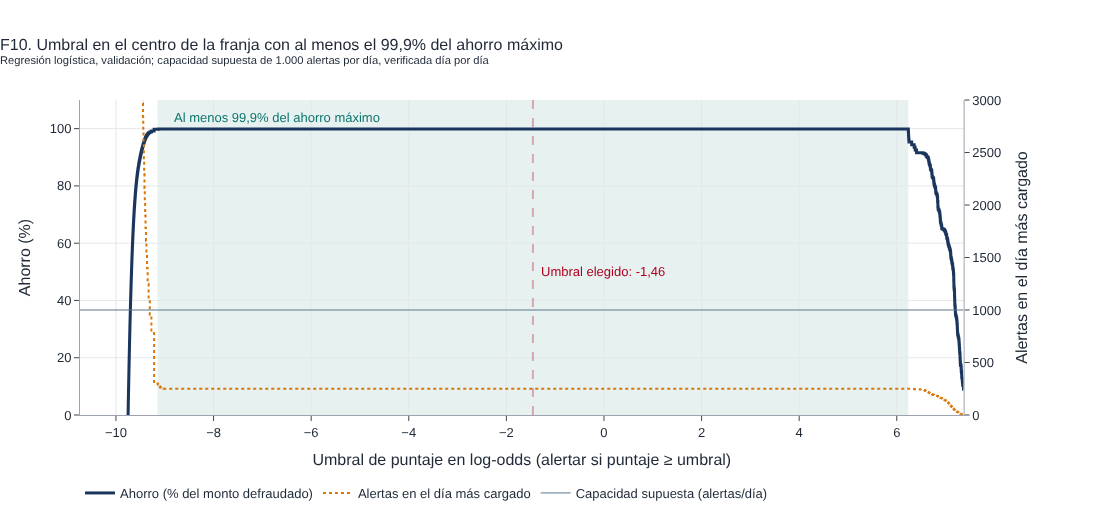

Figura guardada en outputs/figures/F10_umbral_economico.html y .png


In [17]:
# 8.1 Optimización exacta del umbral en validación para el campeón y el retador
C_REV, C_FRIC, CAP_DIA = 1_500.0, 8_500.0, 1_000.0
dias_va, dias_te = dia_all[va], dia_all[te]

def curva_ahorro(y, s, monto, dias, c_rev=C_REV, c_fric=C_FRIC, cap=CAP_DIA, cuenta=None):
    """Ahorro y alertas para cada umbral posible. dias = día de cada operación. Un umbral es factible si ningún día supera el cupo.
    cuenta = máscara de las operaciones que ocupan cupo (por defecto, todas)."""
    orden = np.argsort(-s, kind="mergesort")
    ss, yy, mm = s[orden], y[orden], monto[orden]
    tp, fp, salv = np.cumsum(yy), np.cumsum(1 - yy), np.cumsum(mm * yy)
    ult = np.r_[ss[1:] != ss[:-1], True]           # último elemento de cada grupo de puntajes empatados
    c = pd.DataFrame({"umbral": ss[ult], "tp": tp[ult], "fp": fp[ult], "salvado": salv[ult]})
    dd = np.asarray(dias)[orden]
    ocupa = np.ones(len(dd), dtype=bool) if cuenta is None else np.asarray(cuenta)[orden]
    max_diario = np.zeros(int(ult.sum()), dtype=np.int64)
    for d_ in np.unique(dd):
        max_diario = np.maximum(max_diario, np.cumsum((dd == d_) & ocupa)[ult])
    c["alertas_dia"] = (c["tp"] + c["fp"]) / len(np.unique(dd))    # promedio diario: solo descriptivo
    c["max_diario"] = max_diario
    c["ahorro"] = c["salvado"] - c_rev * (c["tp"] + c["fp"]) - c_fric * c["fp"]
    c["factible"] = c["max_diario"] <= cap
    return c

def evaluar(y, alerta, monto, n_dias, c_rev=C_REV, c_fric=C_FRIC):
    """Resultado económico de un vector booleano de alertas atendidas."""
    a = np.asarray(alerta, dtype=bool)
    tp, fp = int((a & (y == 1)).sum()), int((a & (y == 0)).sum())
    salv = monto[a & (y == 1)].sum()
    return dict(alertas=int(a.sum()), tp=tp, fp=fp, fn=int(y.sum()) - tp, alertas_dia=a.sum() / n_dias,
                sens=tp / y.sum(), prec=tp / a.sum() if a.sum() else np.nan,
                salvado=salv, ahorro=salv - c_rev * a.sum() - c_fric * fp)

def umbral_optimo(y, s, monto, dias, c_rev=C_REV, c_fric=C_FRIC, cap=CAP_DIA, tol=0.999, cuenta=None):
    """Franja = umbrales factibles con ahorro >= 99,9% del máximo factible; el umbral elegido es su punto medio."""
    c = curva_ahorro(y, s, monto, dias, c_rev, c_fric, cap, cuenta)
    n_dias = len(np.unique(dias))
    f = c[c["factible"]]
    if f.empty or f["ahorro"].max() <= 0:          # ningún umbral factible ahorra: no se alerta
        u = float(np.nextafter(np.max(s), np.inf))
        return {"umbral": u, "franja_min": u, "franja_max": u, **evaluar(y, s >= u, monto, n_dias, c_rev, c_fric)}, c
    franja = f[f["ahorro"] >= tol * f["ahorro"].max()]
    lo, hi = float(franja["umbral"].min()), float(franja["umbral"].max())
    u = (lo + hi) / 2
    # Si el punto medio cae en un hueco (un umbral intermedio no factible o con menos ahorro), se usa el candidato admisible más cercano
    efectivo = c.loc[c["umbral"] >= u].iloc[-1]
    if not efectivo["factible"] or efectivo["ahorro"] < tol * f["ahorro"].max():
        u = float(franja.loc[(franja["umbral"] - u).abs().idxmin(), "umbral"])
    return {"umbral": u, "franja_min": lo, "franja_max": hi, **evaluar(y, s >= u, monto, n_dias, c_rev, c_fric)}, c

def atender_por_dia(candidatas, dia, cupo=CAP_DIA):
    """Cola de atención: cada día se atienden las primeras `cupo` alertas en el orden del archivo."""
    candidatas = np.asarray(candidatas, dtype=bool)
    turno = pd.Series(candidatas).groupby(np.asarray(dia), sort=False).cumsum().to_numpy()
    return candidatas & (turno <= cupo)

def a_prob(fam, u):
    """Traduce un umbral de puntaje a probabilidad (los puntajes log-odds pasan por la sigmoide)."""
    return 1 / (1 + np.exp(-u)) if fam in ("Regresión logística", "LDA", "QDA", "XGBoost") else u

UMBRAL, FRANJA, curvas = {}, {}, {}
filas = []
for fam in (CAMPEON, RETADOR):
    o, c = umbral_optimo(y_va, s_va[fam], m_va, dias_va)
    UMBRAL[fam], FRANJA[fam], curvas[fam] = o["umbral"], (o["franja_min"], o["franja_max"]), c
    por_dia = pd.Series(s_va[fam] >= o["umbral"]).groupby(dias_va).sum()
    assert por_dia.max() <= CAP_DIA
    filas.append({"Modelo": fam, "Umbral (puntaje)": o["umbral"], "Umbral (probabilidad)": a_prob(fam, o["umbral"]),
                  "Franja 99,9%: umbral mín.": o["franja_min"], "Franja 99,9%: umbral máx.": o["franja_max"],
                  "Alertas/día (promedio)": o["alertas_dia"], "Alertas/día (máximo)": int(por_dia.max()), "Sensibilidad (%)": o["sens"] * 100,
                  "Precisión (%)": o["prec"] * 100, "Ahorro (% del monto defraudado)": o["ahorro"] / m_va[y_va == 1].sum() * 100})
umb = pd.DataFrame(filas)
umb.to_csv(TAB_DIR / "tabla_umbral_optimo_validacion.csv", index=False)
display(umb.style.format({"Umbral (puntaje)": "{:.4f}", "Umbral (probabilidad)": "{:.6f}", "Franja 99,9%: umbral mín.": "{:.4f}",
                          "Franja 99,9%: umbral máx.": "{:.4f}", "Alertas/día (promedio)": "{:.1f}", "Sensibilidad (%)": "{:.2f}",
                          "Precisión (%)": "{:.2f}", "Ahorro (% del monto defraudado)": "{:.3f}"}))
for _, f in umb.iterrows():
    print(f"{f['Modelo']}: el ahorro alcanza al menos el 99,9% del máximo para cualquier umbral de puntaje entre {f_num(f['Franja 99,9%: umbral mín.'], 3)} y "
          f"{f_num(f['Franja 99,9%: umbral máx.'], 3)}; se adopta el punto medio, {f_num(f['Umbral (puntaje)'], 3)} (probabilidad {f_num(f['Umbral (probabilidad)'], 4)}). "
          f"Ningún día de validación supera el cupo (máximo: {int(f['Alertas/día (máximo)'])} alertas).")

# Qué fija cada borde de la franja del campeón
sv_c = s_va[CAMPEON]; lo_m, hi_m = FRANJA[CAMPEON]
min_fr, max_lg = sv_c[y_va == 1].min(), sv_c[y_va == 0].max()
print(f"Bordes de la franja del campeón. Superior ({f_num(hi_m, 3)}): es el puntaje del fraude de validación con menor puntaje ({f_num(min_fr, 3)}); "
      f"un umbral apenas mayor ya deja pasar un fraude. Inferior ({f_num(lo_m, 3)}): por debajo de la legítima de mayor puntaje ({f_num(max_lg, 3)}) "
      f"la tolerancia del 0,1% admite retener a {f_int((sv_c[y_va == 0] >= lo_m).sum())} clientes honestos.")
print(f"Entre {f_num(max_lg, 3)} y {f_num(min_fr, 3)} todos los umbrales producen exactamente las mismas alertas en validación ({f_int((sv_c >= min_fr).sum())} "
      "fraudes y ninguna legítima): la validación no puede ordenarlos. Elegir uno es un criterio de extrapolación, no una optimización.")
print("Por qué el punto medio: cada borde queda pegado a operaciones concretas de validación; el centro deja el máximo margen a ambos lados frente a "
      "lo que no se vio (un fraude con puntaje algo menor o una legítima con puntaje algo mayor). Este criterio se adoptó después de observar la "
      "prueba: la versión original usaba el borde superior. Las celdas 8.2 y 8.3 cuantifican la diferencia.")

c = curvas[CAMPEON].copy()
c["ahorro_pct"] = c["ahorro"] / m_va[y_va == 1].sum() * 100
c = c[(c["umbral"] >= lo_m - 4) & (c["umbral"] <= hi_m + 6)]
izq, der = c[c["umbral"] < lo_m], c[c["umbral"] >= lo_m]   # se submuestrea solo la zona densa (izquierda); la franja y la derecha se grafican completas
c = pd.concat([izq.iloc[np.unique(np.linspace(0, len(izq) - 1, 1500).astype(int))] if len(izq) else izq, der]).sort_values("umbral")
fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_shape(type="rect", xref="x", yref="paper", x0=lo_m, x1=hi_m, y0=0, y1=1, fillcolor=COLOR_OK, opacity=0.10, line_width=0, layer="below")
fig.add_shape(type="line", xref="x", yref="paper", x0=UMBRAL[CAMPEON], x1=UMBRAL[CAMPEON], y0=0, y1=1, line=dict(color=COLOR_FRAUD, dash="dash", width=2))
fig.add_scatter(x=c["umbral"], y=c["ahorro_pct"], mode="lines", name="Ahorro (% del monto defraudado)", line=dict(color=COLOR_LEGIT, width=3, shape="vh"))
fig.add_scatter(x=c["umbral"], y=c["max_diario"], mode="lines", name="Alertas en el día más cargado", line=dict(color=COLOR_ACCENT, dash="dot", width=2, shape="vh"), secondary_y=True)
fig.add_scatter(x=[c["umbral"].min(), c["umbral"].max()], y=[CAP_DIA, CAP_DIA], mode="lines", name="Capacidad supuesta (alertas/día)",
                line=dict(color=COLOR_NEUTRAL, width=1), secondary_y=True)
fig.add_annotation(x=lo_m + 0.3, y=104, text="Al menos 99,9% del ahorro máximo", showarrow=False, xanchor="left", font=dict(color=COLOR_OK))
fig.add_annotation(x=UMBRAL[CAMPEON], y=50, text=f"Umbral elegido: {UMBRAL[CAMPEON]:.2f}".replace(".", ","), showarrow=False,
                   xanchor="left", xshift=6, font=dict(color=COLOR_FRAUD))
fig.update_layout(title=f"F10. Umbral en el centro de la franja con al menos el 99,9% del ahorro máximo<br><sup>{CAMPEON}, validación; capacidad supuesta de {f_int(CAP_DIA)} alertas por día, verificada día por día</sup>",
                  margin=dict(t=100, b=90), height=490,
                  legend=dict(orientation="h", y=-0.2))
fig.update_xaxes(title_text="Umbral de puntaje en log-odds (alertar si puntaje ≥ umbral)")
fig.update_yaxes(title_text="Ahorro (%)", range=[0, 110], secondary_y=False)
fig.update_yaxes(title_text="Alertas en el día más cargado", secondary_y=True, showgrid=False, range=[0, 3 * CAP_DIA],
                 tickmode="array", tickvals=[0, 500, 1000, 1500, 2000, 2500, 3000])
fig.show(); guardar_fig(fig, "F10_umbral_economico")

In [18]:
# 8.2 Sensibilidad: para cada escenario se vuelve a optimizar el umbral en validación y se aplica en prueba con la cola diaria
ESCENARIOS = [("Base", 1, 1, 1)] + [(f"Revisión x{k}", k, 1, 1) for k in (0.5, 2, 5)] + \
             [(f"Fricción x{k}", 1, k, 1) for k in (0.5, 2, 5)] + [(f"Capacidad x{k}", 1, 1, k) for k in (0.5, 2)] + \
             [("Fricción x20", 1, 20, 1), ("Capacidad 50 por día", 1, 1, 0.05)]
assert np.all(np.diff(step_all[te]) >= 0)   # el archivo está ordenado por hora: la cola respeta el orden de llegada
filas = []
fraude_te = m_te[y_te == 1].sum()
def fila_sens(nombre, u, c_rev, c_fric, cap):
    cand = s_te[CAMPEON] >= u
    aten = atender_por_dia(cand, dias_te, cap)
    assert pd.Series(aten).groupby(dias_te).sum().max() <= cap
    e = evaluar(y_te, aten, m_te, DIAS["Prueba"], c_rev, c_fric)
    return {"Escenario": nombre, "Revisión (u.m.)": c_rev, "Fricción (u.m.)": c_fric, "Capacidad/día": cap,
            "Umbral elegido en validación": u, "Candidatas en prueba": int(cand.sum()), "Atendidas/día en prueba": e["alertas_dia"],
            "Fraudes no detenidos": e["fn"], "Sensibilidad prueba (%)": e["sens"] * 100, "Precisión prueba (%)": e["prec"] * 100,
            "Falsos positivos prueba": e["fp"], "Ahorro prueba (% del monto defraudado)": e["ahorro"] / fraude_te * 100}, cand, aten
for nombre, kr, kf, kc in ESCENARIOS:
    cap = int(CAP_DIA * kc)
    o, _ = umbral_optimo(y_va, s_va[CAMPEON], m_va, dias_va, C_REV * kr, C_FRIC * kf, cap)
    por_dia = pd.Series(s_va[CAMPEON] >= o["umbral"]).groupby(dias_va).sum()
    assert por_dia.max() <= cap
    f_, cand, aten = fila_sens(nombre, o["umbral"], C_REV * kr, C_FRIC * kf, cap)
    filas.append(f_)
    if nombre == "Capacidad 50 por día":
        sin_cola = evaluar(y_te, cand, m_te, DIAS["Prueba"])
        txt_cupo50 = (f"Capacidad de 50 por día: el umbral sube a {f_num(o['umbral'], 3)}, con {', '.join(str(int(v)) for v in por_dia.iloc[:-1])} y {int(por_dia.iloc[-1])} alertas en los tres días de "
                      f"validación. En prueba hay {f_int(cand.sum())} candidatas; se atienden {f_int(aten.sum())} ({cap} por día) y {f_int((cand & ~aten).sum())} quedan "
                      f"sin intervención. Ahorro: {f_num(f_['Ahorro prueba (% del monto defraudado)'], 2)}% "
                      f"(sería {f_num(100 * sin_cola['ahorro'] / fraude_te, 2)}% si se atendieran todas).")
f_borde, _, _ = fila_sens("Base, umbral en el borde superior de la franja (regla original)", FRANJA[CAMPEON][1], C_REV, C_FRIC, int(CAP_DIA))
filas.append(f_borde)
sens = pd.DataFrame(filas)
sens.to_csv(TAB_DIR / "tabla_sensibilidad_economica.csv", index=False)
display(sens.style.format({"Revisión (u.m.)": "{:,.0f}", "Fricción (u.m.)": "{:,.0f}", "Capacidad/día": "{:,.0f}",
                           "Umbral elegido en validación": "{:.3f}", "Candidatas en prueba": "{:,}", "Atendidas/día en prueba": "{:.1f}",
                           "Sensibilidad prueba (%)": "{:.2f}", "Precisión prueba (%)": "{:.2f}", "Ahorro prueba (% del monto defraudado)": "{:.3f}"}))
base_ = sens.iloc[0]; borde_ = sens.iloc[-1]; sens_c = sens.iloc[:-1]
print(f"Regla del umbral: con el centro de la franja el campeón deja pasar {int(base_['Fraudes no detenidos'])} fraudes en prueba; "
      f"con el borde superior deja pasar {int(borde_['Fraudes no detenidos'])} y el ahorro baja de "
      f"{f_num(base_.iloc[-1], 2)}% a {f_num(borde_.iloc[-1], 2)}%. El borde fue la regla original; el centro se adoptó después de observar esta diferencia. "
      f"Por eso {f_num(base_.iloc[-1], 2)}% es un resultado retrospectivo y {f_num(borde_.iloc[-1], 2)}% es la cifra conservadora.")
costos = sens_c[sens_c["Capacidad/día"] >= CAP_DIA * 0.5]
print(f"En los {len(costos)} escenarios de costos y de capacidad entre 500 y 2.000 alertas por día, el ahorro en prueba se ubica entre "
      f"{f_num(costos.iloc[:, -1].min(), 2)}% y {f_num(costos.iloc[:, -1].max(), 2)}% del monto defraudado, "
      f"y el umbral elegido entre {f_num(costos['Umbral elegido en validación'].min(), 2)} y {f_num(costos['Umbral elegido en validación'].max(), 2)}.")
print(txt_cupo50)
print("Lectura: los costos operativos son pequeños frente al monto medio de un fraude, por lo que la conclusión económica es robusta a "
      "multiplicar los costos por 5 o incluso por 20. La capacidad solo condiciona la decisión cuando se la reduce a niveles muy bajos.")

# 8.3 Control de la regla del umbral con datos anteriores a la prueba (validación anidada dentro de los días 1 a 15)
# Para cada origen: entrenar, elegir el umbral con los 3 días siguientes y medirlo en los 3 días posteriores.
hp_c = mejor.set_index("Familia").loc[CAMPEON, "_hp"]
filas = []
for etq, fin_tr, fin_va, fin_ev in [("Entrena 1-6, elige en 7-9, mide en 10-12", 144, 216, 288), ("Entrena 1-9, elige en 10-12, mide en 13-15", 216, 288, 360)]:
    mtr, mva, mev = step_all <= fin_tr, (step_all > fin_tr) & (step_all <= fin_va), (step_all > fin_va) & (step_all <= fin_ev)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=UserWarning)
        m_ = FAMILIAS[CAMPEON][0](**hp_c).fit(X_all[mtr], y_all[mtr])
    o_, _ = umbral_optimo(y_all[mva], puntaje(m_, X_all[mva]), monto_all[mva], dia_all[mva])
    s_ev = puntaje(m_, X_all[mev])
    for regla_u, u_ in [("Borde superior", o_["franja_max"]), ("Punto medio", o_["umbral"])]:
        e_ = evaluar(y_all[mev], atender_por_dia(s_ev >= u_, dia_all[mev]), monto_all[mev], 3)
        filas.append({"Origen": etq, "Regla": regla_u, "Umbral": u_, "Fraudes": int(y_all[mev].sum()), "Fraudes no detenidos": e_["fn"],
                      "Falsos positivos": e_["fp"], "Monto no detenido (u.m.)": monto_all[mev][y_all[mev] == 1].sum() - e_["salvado"],
                      "Ahorro (%)": e_["ahorro"] / monto_all[mev][y_all[mev] == 1].sum() * 100})
anid = pd.DataFrame(filas)
anid.to_csv(TAB_DIR / "tabla_regla_umbral_validacion_anidada.csv", index=False)
display(anid.style.format({"Umbral": "{:.3f}", "Monto no detenido (u.m.)": "{:,.0f}", "Ahorro (%)": "{:.4f}"}))
tot = anid.groupby("Regla")[["Fraudes no detenidos", "Falsos positivos", "Monto no detenido (u.m.)"]].sum()
ah = anid.pivot(index="Origen", columns="Regla", values="Ahorro (%)")
dif_ah = (ah["Punto medio"] - ah["Borde superior"])
print(f"Con datos anteriores a la prueba, el punto medio deja pasar {int(tot.loc['Punto medio', 'Fraudes no detenidos'])} fraudes y el borde superior "
      f"{int(tot.loc['Borde superior', 'Fraudes no detenidos'])} (sobre {f_int(anid.drop_duplicates('Origen')['Fraudes'].sum())}); ninguno retiene clientes honestos "
      f"({int(tot['Falsos positivos'].sum())} falsos positivos). El monto no detenido es {f_num(tot.loc['Punto medio', 'Monto no detenido (u.m.)'], 0)} u.m. con el punto medio y "
      f"{f_num(tot.loc['Borde superior', 'Monto no detenido (u.m.)'], 0)} u.m. con el borde, y el ahorro difiere entre {f_num(dif_ah.min(), 4)} y {f_num(dif_ah.max(), 4)} "
      "puntos porcentuales (punto medio menos borde).")
print("Lectura: antes de la prueba las dos reglas eran prácticamente equivalentes. Esta evidencia es compatible con el punto medio, pero no alcanza "
      "por sí sola para preferirlo: la diferencia material apareció en la prueba, y por eso se informan los dos resultados.")

,Escenario,Revisión (u.m.),Fricción (u.m.),Capacidad/día,Umbral elegido en validación,Candidatas en prueba,Atendidas/día en prueba,Fraudes no detenidos,Sensibilidad prueba (%),Precisión prueba (%),Falsos positivos prueba,Ahorro prueba (% del monto defraudado)
0,Base,"1,500","8,500","1,000",-1.456,"4,193",262.1,3,99.93,100.00,0,99.641
1,Revisión x0.5,750,"8,500","1,000",-1.458,"4,193",262.1,3,99.93,100.00,0,99.689
2,Revisión x2,"3,000","8,500","1,000",-1.452,"4,193",262.1,3,99.93,100.00,0,99.545
3,Revisión x5,"7,500","8,500","1,000",-1.440,"4,193",262.1,3,99.93,100.00,0,99.258
4,Fricción x0.5,"1,500","4,250","1,000",-1.463,"4,193",262.1,3,99.93,100.00,0,99.641
5,Fricción x2,"1,500","17,000","1,000",-1.435,"4,193",262.1,3,99.93,100.00,0,99.641
6,Fricción x5,"1,500","42,500","1,000",-1.413,"4,193",262.1,3,99.93,100.00,0,99.641
7,Capacidad x0.5,"1,500","8,500",500,-1.456,"4,193",262.1,3,99.93,100.00,0,99.641
8,Capacidad x2,"1,500","8,500","2,000",-1.456,"4,193",262.1,3,99.93,100.00,0,99.641
9,Fricción x20,"1,500","170,000","1,000",-1.384,"4,193",262.1,3,99.93,100.00,0,99.641


Regla del umbral: con el centro de la franja el campeón deja pasar 3 fraudes en prueba; con el borde superior deja pasar 12 y el ahorro baja de 99,64% a 98,42%. El borde fue la regla original; el centro se adoptó después de observar esta diferencia. Por eso 99,64% es un resultado retrospectivo y 98,42% es la cifra conservadora.
En los 10 escenarios de costos y de capacidad entre 500 y 2.000 alertas por día, el ahorro en prueba se ubica entre 99,26% y 99,69% del monto defraudado, y el umbral elegido entre -1,46 y -1,38.
Capacidad de 50 por día: el umbral sube a 7,187, con 49, 43 y 44 alertas en los tres días de validación. En prueba hay 1.047 candidatas; se atienden 800 (50 por día) y 247 quedan sin intervención. Ahorro: 31,79% (sería 50,34% si se atendieran todas).
Lectura: los costos operativos son pequeños frente al monto medio de un fraude, por lo que la conclusión económica es robusta a multiplicar los costos por 5 o incluso por 20. La capacidad solo condiciona la decisión cuando s

,Origen,Regla,Umbral,Fraudes,Fraudes no detenidos,Falsos positivos,Monto no detenido (u.m.),Ahorro (%)
0,"Entrena 1-6, elige en 7-9, mide en 10-12",Borde superior,5.290,842,4,0,"135,195",99.8860
1,"Entrena 1-6, elige en 7-9, mide en 10-12",Punto medio,-1.781,842,2,0,"134,984",99.8858
2,"Entrena 1-9, elige en 10-12, mide en 13-15",Borde superior,5.916,738,0,0,0,99.8983
3,"Entrena 1-9, elige en 10-12, mide en 13-15",Punto medio,-1.584,738,0,0,0,99.8983


Con datos anteriores a la prueba, el punto medio deja pasar 2 fraudes y el borde superior 4 (sobre 1.580); ninguno retiene clientes honestos (0 falsos positivos). El monto no detenido es 134.984 u.m. con el punto medio y 135.195 u.m. con el borde, y el ahorro difiere entre -0,0002 y 0,0000 puntos porcentuales (punto medio menos borde).
Lectura: antes de la prueba las dos reglas eran prácticamente equivalentes. Esta evidencia es compatible con el punto medio, pero no alcanza por sí sola para preferirlo: la diferencia material apareció en la prueba, y por eso se informan los dos resultados.


## Sección 9. Evaluación final (días 16 a 31)
Se comparan el escenario sin sistema, las tres líneas de base, el campeón y el retador, cada uno con su umbral de validación. Sensibilidad, precisión, revisiones y ahorro se calculan sobre las alertas atendidas (hasta 1.000 por día); la PR-AUC describe el puntaje antes del cupo. El resultado del campeón corresponde al punto medio, adoptado después de observar la prueba; la referencia conservadora es el borde superior (celda 8.2). Intervalos de Wilson para sensibilidad y precisión; *bootstrap* por bloques de días para PR-AUC y ahorro.

In [19]:
# 9.1 Tabla final de estrategias en prueba
candidatas = {"Sin sistema": np.zeros(te.sum(), dtype=bool)}
candidatas.update({k: v[te] for k, v in reglas.items()})
candidatas[f"{CAMPEON} (campeón)"] = s_te[CAMPEON] >= UMBRAL[CAMPEON]
candidatas[f"{RETADOR} (retador)"] = s_te[RETADOR] >= UMBRAL[RETADOR]
# Cada día se atienden como máximo las primeras 1.000 alertas (orden del archivo); el resto queda sin intervención
estrategias = {nombre: atender_por_dia(alerta, dias_te) for nombre, alerta in candidatas.items()}
leg_te = int((y_te == 0).sum())
filas = []
for nombre, a in estrategias.items():
    tp, fp = int((a & (y_te == 1)).sum()), int((a & (y_te == 0)).sum())
    salv = m_te[a & (y_te == 1)].sum(); ahorro = salv - C_REV * a.sum() - C_FRIC * fp
    lo_s, hi_s = wilson(tp, int(y_te.sum())); lo_p, hi_p = wilson(tp, int(a.sum())) if a.sum() else (np.nan, np.nan)
    filas.append({"Estrategia": nombre, "Candidatas": int(candidatas[nombre].sum()), "Alertas atendidas/día": a.sum() / DIAS["Prueba"], "Fraudes detectados": tp, "Fraudes no detectados": int(y_te.sum()) - tp,
                  "Falsos positivos": fp, "Sensibilidad (%)": tp / y_te.sum() * 100, "IC 95% sensibilidad": f"{lo_s*100:.2f} a {hi_s*100:.2f}",
                  "Precisión (%)": tp / a.sum() * 100 if a.sum() else np.nan,
                  "IC 95% precisión": f"{lo_p*100:.2f} a {hi_p*100:.2f}" if a.sum() else "—",
                  "Tasa de falsos positivos (por millón)": fp / leg_te * 1e6,
                  "Monto salvado (millones u.m.)": salv / 1e6, "Ahorro neto (millones u.m.)": ahorro / 1e6, "Ahorro (%)": ahorro / fraude_te * 100})
final = pd.DataFrame(filas)
final.to_csv(TAB_DIR / "tabla_evaluacion_final_prueba.csv", index=False)
display(final.style.format({"Candidatas": "{:,}", "Alertas atendidas/día": "{:.1f}", "Fraudes detectados": "{:,}", "Fraudes no detectados": "{:,}", "Falsos positivos": "{:,}",
                            "Sensibilidad (%)": "{:.2f}", "Precisión (%)": "{:.2f}", "Tasa de falsos positivos (por millón)": "{:.1f}",
                            "Monto salvado (millones u.m.)": "{:,.1f}", "Ahorro neto (millones u.m.)": "{:,.1f}", "Ahorro (%)": "{:.2f}"}, na_rep="—"))
fc = final.set_index("Estrategia")
print(f"Monto defraudado en prueba sin sistema: {f_num(fraude_te / 1e6, 1)} millones de u.m. en {f_int(y_te.sum())} fraudes.")
for nombre, cand in candidatas.items():
    if cand.sum() > estrategias[nombre].sum():
        sin_cupo = evaluar(y_te, cand, m_te, DIAS["Prueba"]); con_cupo = evaluar(y_te, estrategias[nombre], m_te, DIAS["Prueba"])
        print(f"{nombre}: {f_int(sin_cupo['alertas'])} candidatas en prueba, de las que se atienden {f_int(con_cupo['alertas'])} por el cupo de {f_int(CAP_DIA)} diarias "
              f"({f_int(con_cupo['tp'])} fraudes y {f_int(con_cupo['fp'])} falsos positivos). Ahorro con cupo: {f_num(100 * con_cupo['ahorro'] / fraude_te, 2)}%; "
              f"si se revisaran todas ({f_int(sin_cupo['fp'])} falsos positivos): {f_num(100 * sin_cupo['ahorro'] / fraude_te, 2)}%.")
max_dia = {nombre: int(pd.Series(cand).groupby(dias_te).sum().max()) for nombre, cand in candidatas.items()}
print(f"Día más cargado en prueba: {max_dia[f'{CAMPEON} (campeón)']} alertas del campeón y {max_dia[f'{RETADOR} (retador)']} del retador; "
      "el cupo no los restringe en ningún día.")

,Estrategia,Candidatas,Alertas atendidas/día,Fraudes detectados,Fraudes no detectados,Falsos positivos,Sensibilidad (%),IC 95% sensibilidad,Precisión (%),IC 95% precisión,Tasa de falsos positivos (por millón),Monto salvado (millones u.m.),Ahorro neto (millones u.m.),Ahorro (%)
0,Sin sistema,0,0.0,0,"4,196",0,0.00,0.00 a 0.09,—,—,0.0,0.0,0.0,0.00
1,Regla vigente (isFlaggedFraud),13,0.8,13,"4,183",0,0.31,0.18 a 0.53,100.00,77.19 a 100.00,0.0,71.0,70.9,1.08
2,Monto ≥ P99 de entrenamiento,"11,086",335.8,859,"3,337","4,514",20.47,19.28 a 21.72,15.99,15.03 a 16.99,9004.3,"4,728.7","4,682.3",71.23
3,Regla de firmas (vaciamiento o tramo 10 M),"4,193",262.1,"4,193",3,0,99.93,99.79 a 99.98,100.00,99.91 a 100.00,0.0,"6,555.9","6,549.6",99.64
4,Regresión logística (campeón),"4,193",262.1,"4,193",3,0,99.93,99.79 a 99.98,100.00,99.91 a 100.00,0.0,"6,555.9","6,549.6",99.64
5,XGBoost (retador),"4,193",262.1,"4,193",3,0,99.93,99.79 a 99.98,100.00,99.91 a 100.00,0.0,"6,555.9","6,549.6",99.64


Monto defraudado en prueba sin sistema: 6.573,2 millones de u.m. en 4.196 fraudes.
Monto ≥ P99 de entrenamiento: 11.086 candidatas en prueba, de las que se atienden 5.373 por el cupo de 1.000 diarias (859 fraudes y 4.514 falsos positivos). Ahorro con cupo: 71,23%; si se revisaran todas (10.149 falsos positivos): 75,95%.
Día más cargado en prueba: 320 alertas del campeón y 320 del retador; el cupo no los restringe en ningún día.


In [20]:
# 9.2 PR-AUC de prueba e intervalos bootstrap por bloques de días
dias_te = dia_all[te]
dias_unicos = np.unique(dias_te)
idx_por_dia = {d: np.where(dias_te == d)[0] for d in dias_unicos}
rng_b = np.random.default_rng(SEED)
B = 300
boot = {fam: [] for fam in (CAMPEON, RETADOR)}
boot_ahorro = {fam: [] for fam in (CAMPEON, RETADOR)}
for _ in range(B):
    idx = np.concatenate([idx_por_dia[d] for d in rng_b.choice(dias_unicos, size=len(dias_unicos), replace=True)])
    yb, mb = y_te[idx], m_te[idx]
    for fam in boot:
        sb = s_te[fam][idx]
        boot[fam].append(average_precision_score(yb, sb))
        e = evaluar(yb, sb >= UMBRAL[fam], mb, DIAS["Prueba"])   # el cupo no restringe a estos modelos en ningún día (celda 9.1)
        boot_ahorro[fam].append(e["ahorro"] / mb[yb == 1].sum() * 100)
filas = []
for fam in boot:
    filas.append({"Modelo": fam, "PR-AUC prueba": average_precision_score(y_te, s_te[fam]),
                  "IC 95% PR-AUC": f"{np.percentile(boot[fam], 2.5):.5f} a {np.percentile(boot[fam], 97.5):.5f}",
                  "ROC-AUC prueba": roc_auc_score(y_te, s_te[fam]), "Brier prueba": brier_score_loss(y_te, p_te[fam]),
                  "IC 95% ahorro (%)": f"{np.percentile(boot_ahorro[fam], 2.5):.3f} a {np.percentile(boot_ahorro[fam], 97.5):.3f}"})
ap_te = pd.DataFrame(filas)
display(ap_te.style.format({"PR-AUC prueba": "{:.5f}", "ROC-AUC prueba": "{:.6f}", "Brier prueba": "{:.2e}"}))
brier_ref_te = brier_score_loss(y_te, np.full(len(y_te), y_te.mean()))
print(f"Brier en prueba: {ap_te.set_index('Modelo').loc[CAMPEON, 'Brier prueba']:.2e} el campeón y {ap_te.set_index('Modelo').loc[RETADOR, 'Brier prueba']:.2e} el retador, "
      f"frente a {brier_ref_te:.2e} de predecir siempre la prevalencia de prueba. Es mayor que en validación porque los fraudes no detectados reciben "
      "probabilidad casi nula.")
dif = np.array(boot[RETADOR]) - np.array(boot[CAMPEON])
print(f"Diferencia de PR-AUC (retador − campeón) en prueba: {f_num(dif.mean(), 5)}; IC 95% bootstrap: {f_num(np.percentile(dif, 2.5), 5)} a {f_num(np.percentile(dif, 97.5), 5)} "
      f"({B} réplicas por bloques de días).")

,Modelo,PR-AUC prueba,IC 95% PR-AUC,ROC-AUC prueba,Brier prueba,IC 95% ahorro (%)
0,Regresión logística,0.99951,0.99899 a 0.99990,0.999977,5.94e-06,99.285 a 99.898
1,XGBoost,0.99980,0.99941 a 1.00000,0.999990,5.33e-06,99.285 a 99.898


Brier en prueba: 5.94e-06 el campeón y 5.33e-06 el retador, frente a 8.23e-03 de predecir siempre la prevalencia de prueba. Es mayor que en validación porque los fraudes no detectados reciben probabilidad casi nula.
Diferencia de PR-AUC (retador − campeón) en prueba: 0,00030; IC 95% bootstrap: 0,00001 a 0,00070 (300 réplicas por bloques de días).


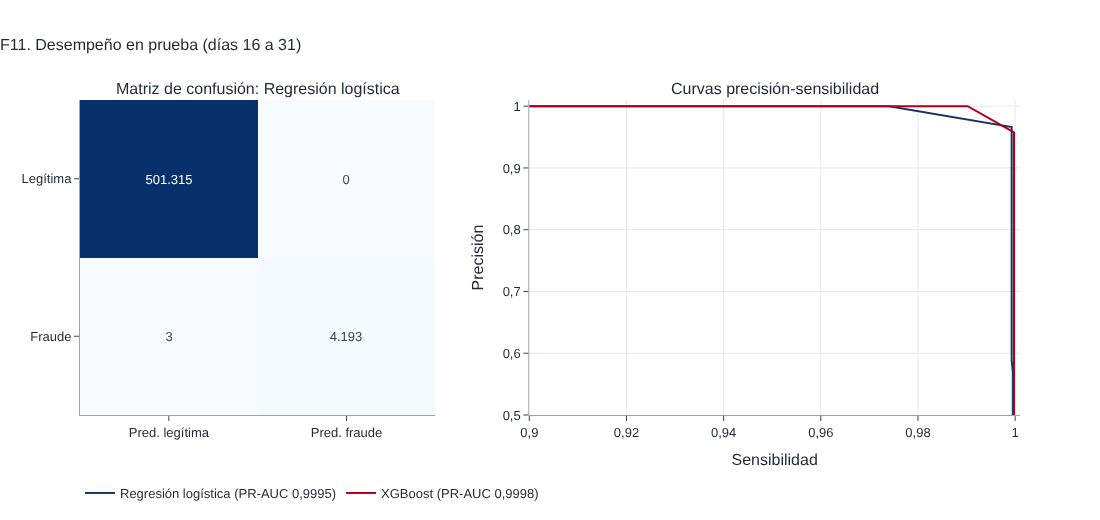

Figura guardada en outputs/figures/F11_prueba_confusion_pr.html y .png


In [21]:
# 9.3 Figura F11: matriz de confusión del campeón y curvas precisión-sensibilidad en prueba
a_c = s_te[CAMPEON] >= UMBRAL[CAMPEON]
cmat = confusion_matrix(y_te, a_c.astype(int))
fig = make_subplots(rows=1, cols=2, subplot_titles=(f"Matriz de confusión: {CAMPEON}", "Curvas precisión-sensibilidad"), column_widths=[0.42, 0.58])
fig.add_heatmap(z=cmat, x=["Pred. legítima", "Pred. fraude"], y=["Legítima", "Fraude"], text=[[f"{v:,}".replace(",", ".") for v in fila] for fila in cmat],
                texttemplate="%{text}", colorscale="Blues", showscale=False, row=1, col=1)
for fam, color in [(CAMPEON, COLOR_LEGIT), (RETADOR, COLOR_FRAUD)]:
    pr_, rc_, _ = precision_recall_curve(y_te, s_te[fam])
    k = np.unique(np.linspace(0, len(pr_) - 1, 2000).astype(int))   # se submuestrea la curva para que el notebook no pese decenas de MB
    pr_, rc_ = pr_[k], rc_[k]
    fig.add_scatter(x=rc_, y=pr_, mode="lines", name=f"{fam} (PR-AUC {average_precision_score(y_te, s_te[fam]):.4f})".replace(".", ","), line=dict(color=color), row=1, col=2)
fig.update_xaxes(title_text="Sensibilidad", range=[0.9, 1.001], row=1, col=2)
fig.update_yaxes(title_text="Precisión", range=[0.5, 1.01], row=1, col=2)
fig.update_yaxes(autorange="reversed", row=1, col=1)
fig.update_layout(title="F11. Desempeño en prueba (días 16 a 31)", height=500, margin=dict(t=100, b=90), legend=dict(orientation="h", y=-0.2))
fig.show(); guardar_fig(fig, "F11_prueba_confusion_pr")

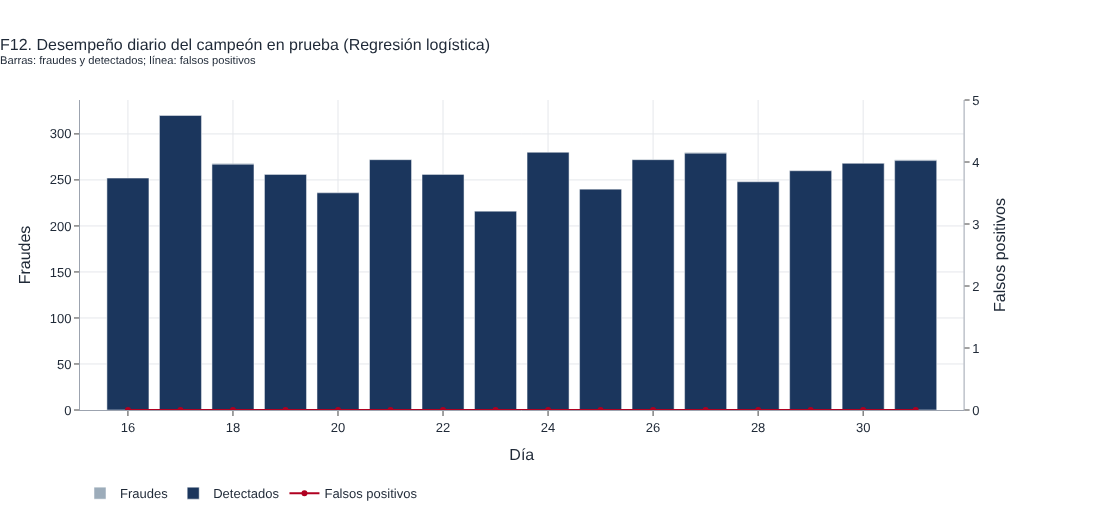

Figura guardada en outputs/figures/F12_desempeno_diario.html y .png
Sensibilidad diaria mínima: 99,63% (día 18); falsos positivos: 0 en todos los días.


,n,vaciamiento exacto,tramo 10 M,saldo de origen 0,monto > saldo,destino con historial,monto mediano
Fraudes no detectados,3,0,0,0,0,0,"7,316,255"
Falsos positivos,0,0,0,0,0,0,—


Fraudes no detectados: 3; de ellos 0 presentan alguna de las firmas y 3 no (monto mediano 7.316.255 u.m.). Falsos positivos: 0.


,step,type,amount,oldbalanceOrg,isFlaggedFraud
354258,425,TRANSFER,9585040.37,19585040.37,1
471115,646,TRANSFER,399045.08,10399045.08,1
505353,730,TRANSFER,7316255.05,17316255.05,1


Fraudes no detectados que la regla vigente sí marca: 3 de 3. Son los remanentes de un tramo de 10 millones (saldo − monto = 10.000.000) descriptos en la sección 7.6 del Notebook 1: combinar el modelo con la regla vigente cubriría todos los fraudes de prueba.


In [22]:
# 9.4 Desempeño diario en prueba y análisis de errores del campeón
diario = pd.DataFrame({"dia": dias_te, "y": y_te, "a": a_c}).groupby("dia").apply(
    lambda g: pd.Series({"fraudes": g["y"].sum(), "detectados": (g["a"] & (g["y"] == 1)).sum(),
                         "falsos_positivos": (g["a"] & (g["y"] == 0)).sum(), "alertas": g["a"].sum()}), include_groups=False)
diario["sensibilidad"] = diario["detectados"] / diario["fraudes"] * 100
fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_bar(x=diario.index, y=diario["fraudes"], name="Fraudes", marker_color=COLOR_NEUTRAL, opacity=0.6)
fig.add_bar(x=diario.index, y=diario["detectados"], name="Detectados", marker_color=COLOR_LEGIT)
fig.add_scatter(x=diario.index, y=diario["falsos_positivos"], name="Falsos positivos", mode="lines+markers", line=dict(color=COLOR_FRAUD), secondary_y=True)
fig.update_layout(title=f"F12. Desempeño diario del campeón en prueba ({CAMPEON})<br><sup>Barras: fraudes y detectados; línea: falsos positivos</sup>",
                  barmode="overlay", height=470, margin=dict(t=100, b=90), legend=dict(orientation="h", y=-0.22))
fig.update_xaxes(title_text="Día"); fig.update_yaxes(title_text="Fraudes", secondary_y=False)
fig.update_yaxes(title_text="Falsos positivos", secondary_y=True, showgrid=False, range=[0, max(5, diario["falsos_positivos"].max() * 1.2)], dtick=1)
fig.show(); guardar_fig(fig, "F12_desempeno_diario")
print(f"Sensibilidad diaria mínima: {f_num(diario['sensibilidad'].min(), 2)}% (día {int(diario['sensibilidad'].idxmin())}); "
      + (f"falsos positivos: 0 en todos los días." if diario['falsos_positivos'].max() == 0 else f"falsos positivos diarios: entre {int(diario['falsos_positivos'].min())} y {int(diario['falsos_positivos'].max())}."))

Xe = X_te.assign(y=y_te, alerta=a_c, monto=m_te)
fn_c, fp_c = Xe[(Xe["y"] == 1) & ~Xe["alerta"]], Xe[(Xe["y"] == 0) & Xe["alerta"]]
def perfil(g):
    return {"n": len(g), "vaciamiento exacto": g["marca_vaciamiento"].sum(), "tramo 10 M": g["tramo_10m_con_saldo"].sum(),
            "saldo de origen 0": g["emisor_sin_saldo"].sum(), "monto > saldo": g["monto_excede_saldo"].sum(),
            "destino con historial": (g["dest_ops_previas_log"] > 0).sum(), "monto mediano": g["monto"].median() if len(g) else np.nan}
display(pd.DataFrame({"Fraudes no detectados": perfil(fn_c), "Falsos positivos": perfil(fp_c)}).T.style.format("{:,.0f}", na_rep="—"))
n_fn_firma = int(((fn_c["marca_vaciamiento"] == 1) | (fn_c["tramo_10m_con_saldo"] == 1)).sum())
print(f"Fraudes no detectados: {len(fn_c)}; de ellos {n_fn_firma} presentan alguna de las firmas y {len(fn_c) - n_fn_firma} no "
      f"(monto mediano {f_num(fn_c['monto'].median(), 0) if len(fn_c) else '—'} u.m.). Falsos positivos: {len(fp_c)}.")
err = r.loc[te].reset_index(drop=True).loc[(y_te == 1) & ~a_c, ["step", "type", "amount", "oldbalanceOrg", "isFlaggedFraud"]]
display(err)
if len(err):
    print(f"Fraudes no detectados que la regla vigente sí marca: {int(err['isFlaggedFraud'].sum())} de {len(err)}. "
          + ("Son los remanentes de un tramo de 10 millones (saldo − monto = 10.000.000) descriptos en la sección 7.6 del Notebook 1: "
             "combinar el modelo con la regla vigente cubriría todos los fraudes de prueba." if err["isFlaggedFraud"].all() else ""))

In [23]:
# 9.5 Tabla resumen: los seis modelos y las tres líneas de base en prueba, cada modelo con su propio umbral elegido en validación
filas = []
for nombre, pred in reglas.items():
    a = estrategias[nombre]   # alertas atendidas con el cupo diario (celda 9.1)
    tp, fp = int((a & (y_te == 1)).sum()), int((a & (y_te == 0)).sum())
    salv = m_te[a & (y_te == 1)].sum()
    filas.append({"Tipo": "Línea de base", "Estrategia": nombre, "Hiperparámetros": "regla fija, sin entrenamiento",
                  "PR-AUC entrenamiento": average_precision_score(y_tr, pred[tr].astype(int)), "PR-AUC validación": average_precision_score(y_va, pred[va].astype(int)),
                  "PR-AUC prueba": average_precision_score(y_te, pred[te].astype(int)),
                  "Sensibilidad (%)": tp / y_te.sum() * 100, "Precisión (%)": tp / a.sum() * 100 if a.sum() else np.nan,
                  "Falsos positivos": fp, "Ahorro (%)": (salv - C_REV * a.sum() - C_FRIC * fp) / fraude_te * 100})
for fam in modelos:
    o, _ = umbral_optimo(y_va, s_va[fam], m_va, dias_va)   # mismo criterio para los seis: cupo verificado día por día
    if fam in UMBRAL:
        assert o["umbral"] == UMBRAL[fam]
    e = evaluar(y_te, atender_por_dia(s_te[fam] >= o["umbral"], dias_te), m_te, DIAS["Prueba"])
    filas.append({"Tipo": "Modelo" + (" (campeón)" if fam == CAMPEON else " (retador)" if fam == RETADOR else ""),
                  "Estrategia": fam, "Hiperparámetros": mejor.set_index("Familia").loc[fam, "Hiperparámetros"],
                  "PR-AUC entrenamiento": average_precision_score(y_tr, s_tr[fam]), "PR-AUC validación": average_precision_score(y_va, s_va[fam]),
                  "PR-AUC prueba": average_precision_score(y_te, s_te[fam]),
                  "Sensibilidad (%)": e["sens"] * 100, "Precisión (%)": e["prec"] * 100, "Falsos positivos": e["fp"],
                  "Ahorro (%)": e["ahorro"] / fraude_te * 100})
resumen = pd.DataFrame(filas)
resumen.to_csv(TAB_DIR / "tabla_resumen_modelos_y_lineas_de_base.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(resumen.style.format({"PR-AUC entrenamiento": "{:.4f}", "PR-AUC validación": "{:.4f}", "PR-AUC prueba": "{:.4f}", "Sensibilidad (%)": "{:.2f}",
                                  "Precisión (%)": "{:.2f}", "Falsos positivos": "{:,}", "Ahorro (%)": "{:.2f}"}))
print("Sensibilidad, precisión, falsos positivos y ahorro corresponden a las alertas atendidas (hasta 1.000 por día). "
      "Para las reglas, la PR-AUC se calcula sobre su señal binaria antes del cupo (equivale a precisión × sensibilidad + (1 − sensibilidad) × prevalencia) "
      "y solo sirve como referencia: una regla no ordena las operaciones.")
mod = resumen[resumen["Tipo"].str.startswith("Modelo")]
print(f"Los seis modelos superan con holgura a la regla vigente y a la heurística de monto alto: su ahorro en prueba va de {f_num(mod['Ahorro (%)'].min(), 2)}% "
      f"a {f_num(mod['Ahorro (%)'].max(), 2)}%, frente a {f_num(resumen.iloc[0]['Ahorro (%)'], 2)}% y {f_num(resumen.iloc[1]['Ahorro (%)'], 2)}%. "
      f"La regla de firmas logra {f_num(resumen.iloc[2]['Ahorro (%)'], 2)}%.")
caida = ((mod["PR-AUC entrenamiento"] - mod["PR-AUC prueba"]) / mod["PR-AUC entrenamiento"] * 100)
print(f"Sobreajuste respecto del período posterior: la variación de la PR-AUC entre entrenamiento y prueba va de {f_num(caida.min(), 2)}% a {f_num(caida.max(), 2)}% "
      "(valores negativos indican mejora en prueba); ningún modelo supera la brecha de 5% fijada en la sección 6.2.")

,Tipo,Estrategia,Hiperparámetros,PR-AUC entrenamiento,PR-AUC validación,PR-AUC prueba,Sensibilidad (%),Precisión (%),Falsos positivos,Ahorro (%)
0,Línea de base,Regla vigente (isFlaggedFraud),"regla fija, sin entrenamiento",0.0028,0.0014,0.0114,0.31,100.00,0,1.08
1,Línea de base,Monto ≥ P99 de entrenamiento,"regla fija, sin entrenamiento",0.0100,0.0026,0.0253,20.47,15.99,"4,514",71.23
2,Línea de base,Regla de firmas (vaciamiento o tramo 10 M),"regla fija, sin entrenamiento",0.9906,1.0000,0.9993,99.93,100.00,0,99.64
3,Modelo (campeón),Regresión logística,"C=0.01, cw=None",0.9918,1.0000,0.9995,99.93,100.00,0,99.64
4,Modelo,LDA,"solver=svd, shrinkage=None",0.9912,1.0000,1.0000,99.93,100.00,0,99.64
5,Modelo,QDA,reg=0.5,0.9909,1.0000,0.9999,99.93,100.00,0,99.64
6,Modelo,Árbol de decisión (CART),depth=4,0.9908,0.9996,1.0000,100.00,99.98,1,99.90
7,Modelo,Random Forest,"depth=8, leaf=100",0.9921,1.0000,1.0000,99.98,100.00,0,99.90
8,Modelo (retador),XGBoost,"depth=3, lr=0.05",0.9948,1.0000,0.9998,99.93,100.00,0,99.64


Sensibilidad, precisión, falsos positivos y ahorro corresponden a las alertas atendidas (hasta 1.000 por día). Para las reglas, la PR-AUC se calcula sobre su señal binaria antes del cupo (equivale a precisión × sensibilidad + (1 − sensibilidad) × prevalencia) y solo sirve como referencia: una regla no ordena las operaciones.
Los seis modelos superan con holgura a la regla vigente y a la heurística de monto alto: su ahorro en prueba va de 99,64% a 99,90%, frente a 1,08% y 71,23%. La regla de firmas logra 99,64%.
Sobreajuste respecto del período posterior: la variación de la PR-AUC entre entrenamiento y prueba va de -0,92% a -0,51% (valores negativos indican mejora en prueba); ningún modelo supera la brecha de 5% fijada en la sección 6.2.


## Sección 10. Robustez
Las firmas son conductas programadas en el simulador: ¿qué pasa si el atacante deja de seguirlas? Primero se reentrena con los mismos hiperparámetros en tres variantes (completa, **sin firmas exactas** y **sin ninguna relación monto-saldo**) y se simula un atacante que retira el 90% del saldo, recalculando los atributos de los fraudes de prueba con la función de la sección 2.3. El umbral de cada variante se elige en validación con el mismo criterio de la sección 8 (cupo verificado día por día).

,Modelo,Atributos,PR-AUC prueba,Sensibilidad prueba (%),PR-AUC con atacante al 90%,Sensibilidad con atacante al 90% (%),Alertas en el día más cargado
0,Regresión logística,Completo,0.9995,99.93,0.0746,0.31,320
1,Regresión logística,Sin firmas exactas,0.7922,80.98,0.7782,79.89,977
2,Regresión logística,Sin relación monto-saldo,0.5901,61.96,0.5843,61.65,1119
3,XGBoost,Completo,0.9998,99.93,0.3447,1.02,320
4,XGBoost,Sin firmas exactas,0.9998,99.98,0.3991,19.61,320
5,XGBoost,Sin relación monto-saldo,0.8394,85.13,0.8088,82.20,756
6,Regla de firmas,Vaciamiento o tramo 10 M,—,99.93,—,0.31,320


La regla de firmas es binaria y no ordena operaciones, por eso no tiene PR-AUC en esta tabla.
Cupo de 1.000 alertas diarias en prueba: lo superan algún día Regresión logística / Sin relación monto-saldo (1.119). Sus sensibilidades corresponden a las alertas atendidas.


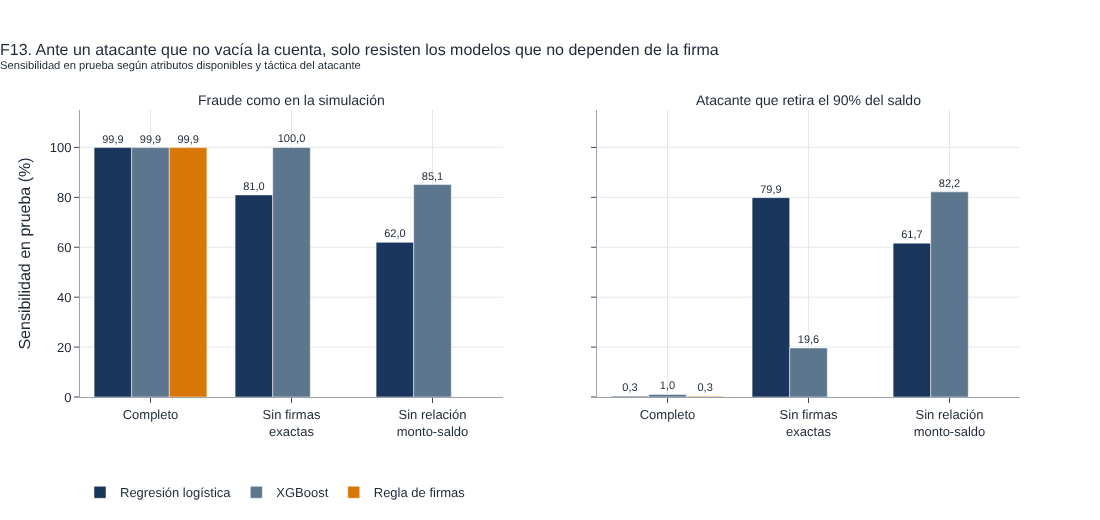

Figura guardada en outputs/figures/F13_ablacion_adversario.html y .png


In [24]:
# 10.1 Ablación y escenario adversario
VARIANTES = {
    "Completo": FEATURES,
    "Sin firmas exactas": [f for f in FEATURES if f not in ("marca_vaciamiento", "tramo_10m_con_saldo")],
    "Sin relación monto-saldo": [f for f in FEATURES if f not in ("marca_vaciamiento", "tramo_10m_con_saldo", "log_ratio_monto_saldo", "monto_excede_saldo")],
}
# Atacante: en los fraudes de prueba con saldo positivo, el monto pasa a ser el 90% del saldo disponible
r_te = r.loc[te].reset_index(drop=True)
es_f = (y_te == 1) & (r_te["oldbalanceOrg"].to_numpy() > 0)
monto_adv = np.where(es_f, 0.9 * r_te["oldbalanceOrg"].to_numpy(), m_te)
X_adv = construir_atributos(monto_adv, r_te["oldbalanceOrg"].to_numpy(), (r_te["type"] == "TRANSFER").to_numpy(),
                            (r_te["step"] % 24).to_numpy(), r_te["ops_previas_168h"].to_numpy(), r_te["monto_previo_168h"].to_numpy())

filas, abl_modelos = [], {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=UserWarning)
    for fam in (CAMPEON, RETADOR):
        hp = mejor.set_index("Familia").loc[fam, "_hp"]
        for var, cols in VARIANTES.items():
            m = modelos[fam] if var == "Completo" else FAMILIAS[fam][0](**hp).fit(X_tr[cols], y_tr)
            u = UMBRAL[fam] if var == "Completo" else umbral_optimo(y_va, puntaje(m, X_va[cols]), m_va, dias_va)[0]["umbral"]
            s_norm, s_adv = puntaje(m, X_te[cols]), puntaje(m, X_adv[cols])
            abl_modelos[(fam, var)] = (m, u, cols)
            # Igual que en la sección 9: cada día se atienden las alertas en orden de llegada hasta completar el cupo
            a_norm, a_adv = atender_por_dia(s_norm >= u, dias_te), atender_por_dia(s_adv >= u, dias_te)
            filas.append({"Modelo": fam, "Atributos": var,
                          "PR-AUC prueba": average_precision_score(y_te, s_norm),
                          "Sensibilidad prueba (%)": (a_norm & (y_te == 1)).sum() / y_te.sum() * 100,
                          "PR-AUC con atacante al 90%": average_precision_score(y_te, s_adv),
                          "Sensibilidad con atacante al 90% (%)": (a_adv & (y_te == 1)).sum() / y_te.sum() * 100,
                          "Alertas en el día más cargado": int(max(pd.Series(s_norm >= u).groupby(dias_te).sum().max(),
                                                                   pd.Series(s_adv >= u).groupby(dias_te).sum().max()))})
regla_norm = (X_te["marca_vaciamiento"].to_numpy() == 1) | (X_te["tramo_10m_con_saldo"].to_numpy() == 1)
regla_adv = (X_adv["marca_vaciamiento"].to_numpy() == 1) | (X_adv["tramo_10m_con_saldo"].to_numpy() == 1)
filas.append({"Modelo": "Regla de firmas", "Atributos": "Vaciamiento o tramo 10 M", "PR-AUC prueba": np.nan,
              "Sensibilidad prueba (%)": (regla_norm & (y_te == 1)).sum() / y_te.sum() * 100, "PR-AUC con atacante al 90%": np.nan,
              "Sensibilidad con atacante al 90% (%)": (regla_adv & (y_te == 1)).sum() / y_te.sum() * 100,
              "Alertas en el día más cargado": int(max(pd.Series(regla_norm).groupby(dias_te).sum().max(), pd.Series(regla_adv).groupby(dias_te).sum().max()))})
abl = pd.DataFrame(filas)
abl.to_csv(TAB_DIR / "tabla_ablacion_adversario.csv", index=False)
display(abl.style.format({c: "{:.4f}" for c in abl.columns if "PR-AUC" in c} | {c: "{:.2f}" for c in abl.columns if "(%)" in c}, na_rep="—"))
print("La regla de firmas es binaria y no ordena operaciones, por eso no tiene PR-AUC en esta tabla.")
_sobre = abl[abl["Alertas en el día más cargado"] > CAP_DIA]
print(f"Cupo de {f_int(CAP_DIA)} alertas diarias en prueba: " + ("ninguna variante lo supera en ningún día "
      f"(máximo: {f_int(abl['Alertas en el día más cargado'].max())}), así que la cola no altera estas sensibilidades." if _sobre.empty else
      "lo superan algún día " + "; ".join(f"{a} / {b} ({f_int(c)})" for a, b, c in _sobre[["Modelo", "Atributos", "Alertas en el día más cargado"]].to_numpy())
      + ". Sus sensibilidades corresponden a las alertas atendidas."))

fig = make_subplots(rows=1, cols=2, shared_yaxes=True, subplot_titles=("Fraude como en la simulación", "Atacante que retira el 90% del saldo"))
orden_var = list(VARIANTES)
for fam, color in [(CAMPEON, COLOR_LEGIT), (RETADOR, COLOR_NEUTRAL), ("Regla de firmas", COLOR_ACCENT)]:
    sub = abl[abl["Modelo"] == fam].copy()
    if fam == "Regla de firmas":
        sub["Atributos"] = "Completo"
    for j_, col in enumerate(["Sensibilidad prueba (%)", "Sensibilidad con atacante al 90% (%)"], start=1):
        fig.add_bar(x=sub["Atributos"], y=sub[col], name=fam, marker_color=color, legendgroup=fam, showlegend=(j_ == 1),
                    text=[f"{v:.1f}".replace(".", ",") for v in sub[col]], textposition="outside", textfont=dict(size=11), row=1, col=j_)
fig.update_xaxes(categoryorder="array", categoryarray=orden_var, tickangle=0, tickmode="array", tickvals=orden_var,
                 ticktext=[v.replace("Sin relación monto-saldo", "Sin relación<br>monto-saldo").replace("Sin firmas exactas", "Sin firmas<br>exactas") for v in orden_var])
fig.update_yaxes(title_text="Sensibilidad en prueba (%)", range=[0, 115], row=1, col=1)
fig.update_annotations(font_size=14)
fig.update_layout(title="F13. Ante un atacante que no vacía la cuenta, solo resisten los modelos que no dependen de la firma<br>"
                        "<sup>Sensibilidad en prueba según atributos disponibles y táctica del atacante</sup>", barmode="group",
                  height=540, margin=dict(t=110, b=110), legend=dict(orientation="h", y=-0.28), uniformtext_minsize=10)
fig.show(); guardar_fig(fig, "F13_ablacion_adversario")

In [25]:
# 10.2 Lectura automática de la ablación
def v(fam, var, col):
    return abl[(abl["Modelo"] == fam) & (abl["Atributos"] == var)][col].iloc[0]
for fam in (CAMPEON, RETADOR):
    print(f"{fam}: sensibilidad {f_num(v(fam, 'Completo', 'Sensibilidad prueba (%)'), 2)}% con fraude simulado y "
          f"{f_num(v(fam, 'Completo', 'Sensibilidad con atacante al 90% (%)'), 2)}% si el atacante retira el 90% del saldo. "
          f"Sin ninguna relación monto-saldo, la PR-AUC de prueba es {f_num(v(fam, 'Sin relación monto-saldo', 'PR-AUC prueba'), 4)}.")
print(f"Regla de firmas: {f_num(v('Regla de firmas', 'Vaciamiento o tramo 10 M', 'Sensibilidad prueba (%)'), 2)}% con fraude simulado y "
      f"{f_num(v('Regla de firmas', 'Vaciamiento o tramo 10 M', 'Sensibilidad con atacante al 90% (%)'), 2)}% ante el atacante.")
print(f"Hallazgo: el modelo {CAMPEON} entrenado sin las firmas exactas rinde menos con el fraude simulado "
      f"({f_num(v(CAMPEON, 'Sin firmas exactas', 'Sensibilidad prueba (%)'), 2)}%) pero conserva "
      f"{f_num(v(CAMPEON, 'Sin firmas exactas', 'Sensibilidad con atacante al 90% (%)'), 2)}% ante el atacante, contra "
      f"{f_num(v(CAMPEON, 'Completo', 'Sensibilidad con atacante al 90% (%)'), 2)}% del modelo completo. La robustez la da no depender de la firma, "
      "no la familia del algoritmo.")
print("Conclusión: ningún modelo es 'resiliente' por sí mismo. El desempeño depende de que el atacante se comporte como en el simulador; "
      "si cambia de táctica, la detección cae y debe recuperarse con monitoreo, nuevas etiquetas y reentrenamiento. Por eso la política "
      "operativa incluye seguimiento de la tasa de alertas y del perfil de los fraudes confirmados (sección 13).")

Regresión logística: sensibilidad 99,93% con fraude simulado y 0,31% si el atacante retira el 90% del saldo. Sin ninguna relación monto-saldo, la PR-AUC de prueba es 0,5901.
XGBoost: sensibilidad 99,93% con fraude simulado y 1,02% si el atacante retira el 90% del saldo. Sin ninguna relación monto-saldo, la PR-AUC de prueba es 0,8394.
Regla de firmas: 99,93% con fraude simulado y 0,31% ante el atacante.
Hallazgo: el modelo Regresión logística entrenado sin las firmas exactas rinde menos con el fraude simulado (80,98%) pero conserva 79,89% ante el atacante, contra 0,31% del modelo completo. La robustez la da no depender de la firma, no la familia del algoritmo.
Conclusión: ningún modelo es 'resiliente' por sí mismo. El desempeño depende de que el atacante se comporte como en el simulador; si cambia de táctica, la detección cae y debe recuperarse con monitoreo, nuevas etiquetas y reentrenamiento. Por eso la política operativa incluye seguimiento de la tasa de alertas y del perfil de los f

### 10.3 Batería de 18 ataques, entrenamiento con ataques y control de madrugada
Se aplican a los 4.196 fraudes de prueba dieciocho escenarios recalculando sus atributos (las legítimas no cambian): **retiros parciales** (de dejar un centavo a retirar el 10%), **cambios que conservan el vaciamiento** (operar de día, retiro en efectivo, destino con historial) y **fraccionamiento** en 2, 3 o 5 transferencias (la cuenta se congela en la primera alerta). Luego se reentrenan la logística y XGBoost con copias sintéticas de los fraudes que retiran entre el 50% y el 99% del saldo; los ataques fuera de ese rango (30%, 10%, fraccionamiento, combinado) miden la generalización real. El umbral de estos modelos se elige en la validación aumentada con el criterio de la sección 8; el cupo diario se verifica sobre las operaciones reales, porque las copias sintéticas son versiones alternativas de los mismos fraudes y no tráfico adicional. Al final se controla la **madrugada**: qué pasa con fraudes y clientes honestos que operan a las 3 h.

Entrenamiento aumentado: 1.742.770 operaciones, de las cuales 13.004 son fraudes sintéticos con retiros parciales (14 s).


Fraudes de prueba detenidos (%) en cada escenario:


Modelo,Regresión logística (campeón),XGBoost (retador),Regla de firmas,Centinela (sin firmas),Regresión logística entrenada con ataques,XGBoost entrenado con ataques
Escenario,,,,,,
Fraude como en los datos,99.9,99.9,99.9,81.0,99.9,100.0
Deja 1 centavo,0.3,0.6,0.3,81.0,82.9,86.8
Deja 1 u.m.,0.3,0.6,0.3,81.0,82.9,86.8
Retira el 99%,0.3,0.6,0.3,80.9,82.8,86.7
Retira el 95%,0.3,1.1,0.3,80.5,82.3,87.2
Retira el 90%,0.3,1.0,0.3,79.9,81.6,86.9
Retira el 80%,0.3,1.0,0.3,78.0,80.2,86.2
Retira el 70%,0.3,0.9,0.3,75.9,78.3,85.7
Retira el 50%,0.3,0.3,0.3,70.7,72.6,78.6


En el fraccionamiento, % del monto protegido (la cuenta se congela en la primera alerta):


Modelo,Regresión logística (campeón),XGBoost (retador),Regla de firmas,Centinela (sin firmas),Regresión logística entrenada con ataques,XGBoost entrenado con ataques
Escenario,,,,,,
Fracciona en 2 transferencias,50.0,50.0,50.0,96.4,97.2,98.4
Fracciona en 3 transferencias,33.3,33.3,33.3,94.4,94.2,77.5
Fracciona en 5 transferencias,20.0,20.0,20.0,91.3,89.7,53.4


,Modelo,Ahorro con fraude como en los datos (%),Ahorro ante atacante del 90% (%),Alertas por día,Clientes honestos retenidos por día,Alertas en el día más cargado
0,Regresión logística (campeón),99.64,-0.00,262.1,0.0,320
1,XGBoost (retador),99.64,3.18,262.1,0.0,320
2,Regla de firmas,99.64,-0.00,262.1,0.0,320
3,Centinela (sin firmas),97.77,97.84,400.0,187.6,977
4,Regresión logística entrenada con ataques,99.41,96.82,464.4,202.3,1101
5,XGBoost entrenado con ataques,99.63,98.45,371.0,108.8,764


Cupo de 1.000 alertas diarias en prueba: lo supera en su día más cargado Regresión logística entrenada con ataques (1.101 alertas), que no integra la arquitectura recomendada; sus cifras describen la señal sin cola. Los demás detectores quedan dentro del cupo todos los días (máximo: 977), así que la cola diaria no altera sus cifras.


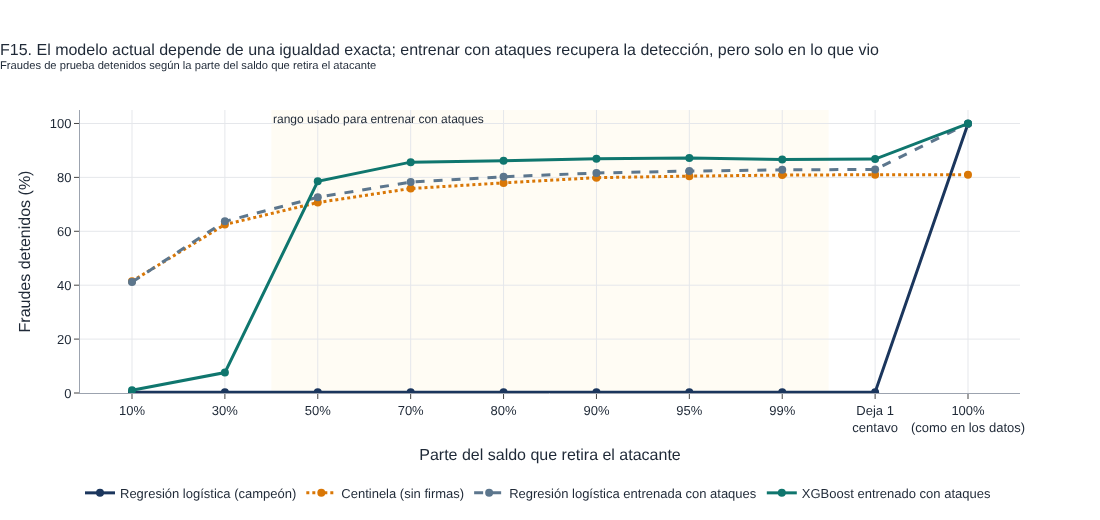

Figura guardada en outputs/figures/F15_bateria_escenarios.html y .png


Control de madrugada:


,Modelo,Fraudes a las 3 h que vacían la cuenta (%),Fraudes a las 3 h que retiran el 90% (%),Legítimas retenidas por día si todas operaran a las 3 h
0,Regresión logística (campeón),99.9,0.3,0.0
1,XGBoost (retador),99.9,0.3,0.0
2,Centinela (sin firmas),96.0,95.5,2123.8
3,Regresión logística entrenada con ataques,100.0,98.0,2253.3
4,XGBoost entrenado con ataques,100.0,100.0,1455.3


Legítimas reales de prueba entre la 1 y las 5 h: 2.226; el campeón retiene 0 y envía 20 a verificación. Si todas las legítimas operaran a las 3 h, retendría 0 y enviaría a verificación 125,6 por día.
1) Con cualquier retiro parcial, incluso dejando un centavo, el campeón detiene 0,3% y la regla de firmas 0,3%: dependen de una igualdad exacta. El XGBoost original detiene entre 0,3% y 1,1% según el retiro (1,0% ante el del 90%). Operar de día o hacia un destino con historial no afecta al campeón (99,9%).
2) Ante el robo fraccionado alerta en la última parte y protege 50,0%, 33,3% y 20,0% del monto con 2, 3 y 5 partes.
3) XGBoost entrenado con ataques detiene 86,9% ante el retiro del 90% y ahorra 98,45% en ese escenario (99,63% en condiciones normales), con 108,8 clientes honestos retenidos por día; fuera del rango entrenado cae a 7,6% y 1,0% (retiros del 30% y del 10%). El centinela conserva 41,5% ante el retiro del 10%.
4) El 10,0% de las legítimas de prueba (50.320) pide menos que el s

In [26]:
# 10.3 Batería de escenarios adversarios y modelos entrenados con ataques sintéticos
rng_adv = np.random.default_rng(SEED)
S_all = r["oldbalanceOrg"].to_numpy(); T_all = (r["type"] == "TRANSFER").to_numpy(); H_all = (r["step"] % 24).to_numpy()
OP_all, MP_all = r["ops_previas_168h"].to_numpy(), r["monto_previo_168h"].to_numpy()
def X_mod(idx, m=None, s=None, t=None, h=None, op=None, mp=None):
    return construir_atributos(monto_all[idx] if m is None else m, S_all[idx] if s is None else s, T_all[idx] if t is None else t,
                               H_all[idx] if h is None else h, OP_all[idx] if op is None else op, MP_all[idx] if mp is None else mp)
i_te = np.where(te)[0]; f_te = i_te[y_all[i_te] == 1]; l_te = i_te[y_all[i_te] == 0]; nf = len(f_te)
X_leg = X_mod(l_te); con_saldo = S_all[f_te] > 0; monto_f = monto_all[f_te]
assert np.allclose(X_mod(f_te)[FEATURES].to_numpy(), X_all[FEATURES].to_numpy()[f_te])
def parcial(frac=None, deja=None):
    s = S_all[f_te]
    if deja is not None:
        return np.where(con_saldo & (s > deja), np.round(s - deja, 2), monto_f)
    return np.where(con_saldo, np.round(frac * s, 2), monto_f)
ESC = [("Fraude como en los datos", X_mod(f_te), monto_f)]
for etq, kw in [("Deja 1 centavo", dict(deja=0.01)), ("Deja 1 u.m.", dict(deja=1.0)), ("Retira el 99%", dict(frac=.99)), ("Retira el 95%", dict(frac=.95)),
                ("Retira el 90%", dict(frac=.90)), ("Retira el 80%", dict(frac=.80)), ("Retira el 70%", dict(frac=.70)), ("Retira el 50%", dict(frac=.50)),
                ("Retira el 30%", dict(frac=.30)), ("Retira el 10%", dict(frac=.10))]:
    m_ = parcial(**kw); ESC.append((etq, X_mod(f_te, m=m_), m_))
op_mula, mp_mula = np.maximum(OP_all[f_te], 6), np.maximum(MP_all[f_te], 210_000.0)
ESC += [("Destino con historial (cuenta intermediaria)", X_mod(f_te, op=op_mula, mp=mp_mula), monto_f),
        ("Opera a las 14 h", X_mod(f_te, h=np.full(nf, 14)), monto_f),
        ("Retiro en efectivo en vez de transferencia", X_mod(f_te, t=np.zeros(nf, bool)), monto_f)]
m90 = parcial(frac=.90)
ESC.append(("Combinado: 90% + destino con historial + 14 h", X_mod(f_te, m=m90, op=op_mula, mp=mp_mula, h=np.full(nf, 14)), m90))
def piezas_fraccion(k):
    s0 = S_all[f_te]; pieza = np.round(np.where(con_saldo, s0 / k, monto_f), 2); out = []
    for j in range(k):
        saldo_j = np.round(np.where(con_saldo, s0 - j * pieza, s0), 2)
        m_j = np.where(con_saldo, np.where(j == k - 1, saldo_j, pieza), monto_f if j == 0 else 0.0)
        X_j = X_mod(f_te, m=np.maximum(m_j, 0), s=saldo_j, h=(H_all[f_te] + j) % 24, op=OP_all[f_te] + j, mp=MP_all[f_te] + j * np.where(con_saldo, pieza, 0))
        out.append((X_j, np.where(con_saldo | (j == 0), m_j, 0.0)))
    return out
FRAC = {f"Fracciona en {k} transferencias": piezas_fraccion(k) for k in (2, 3, 5)}

def evaluar_escenarios(detecta):
    """detecta(X) -> vector booleano de alertas. Devuelve % de fraudes detenidos y % del monto protegido por escenario."""
    out = {}
    for esc, X_e, m_e in ESC:
        d = detecta(X_e); out[esc] = (d.mean() * 100, m_e[d].sum() / m_e.sum() * 100)
    for esc, piezas in FRAC.items():
        cong = np.zeros(nf, bool); robado = np.zeros(nf); total = np.zeros(nf)
        for X_j, m_j in piezas:
            d = detecta(X_j); robado += np.where(~cong & ~d, m_j, 0); cong |= d; total += m_j
        out[esc] = (cong.mean() * 100, (1 - robado.sum() / total.sum()) * 100)
    return out

# Modelos entrenados con ataques sintéticos (aumentación de datos)
def aumentar(mask, copias):
    idx = np.where(mask & (y_all == 1) & (S_all > 0))[0]; Xs, ms = [], []
    for _ in range(copias):
        m_ = np.round(rng_adv.uniform(0.5, 0.99, len(idx)) * S_all[idx], 2); Xs.append(X_mod(idx, m=m_)); ms.append(m_)
    return pd.concat(Xs, ignore_index=True), np.concatenate(ms), np.tile(dia_all[idx], copias)
Xa_tr, _, _ = aumentar(tr, 4); Xa_va, ma_va, da_va = aumentar(va, 2)
X_tr_aum = pd.concat([X_tr.reset_index(drop=True), Xa_tr[FEATURES]], ignore_index=True); y_tr_aum = np.concatenate([y_tr, np.ones(len(Xa_tr), int)])
X_va_aum = pd.concat([X_va.reset_index(drop=True), Xa_va[FEATURES]], ignore_index=True); y_va_aum = np.concatenate([y_va, np.ones(len(Xa_va), int)])
m_va_aum = np.concatenate([m_va, ma_va]); d_va_aum = np.concatenate([dias_va, da_va])
# Las copias sintéticas son versiones alternativas de los mismos fraudes, no tráfico adicional: el cupo diario se verifica sobre las operaciones reales
real_va_aum = np.r_[np.ones(len(y_va), dtype=bool), np.zeros(len(Xa_va), dtype=bool)]
mod_ata, u_ata = {}, {}
t0 = time.perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=UserWarning)
    for fam in (CAMPEON, RETADOR):
        mod_ata[fam] = FAMILIAS[fam][0](**mejor.set_index("Familia").loc[fam, "_hp"]).fit(X_tr_aum, y_tr_aum)
        u_ata[fam] = umbral_optimo(y_va_aum, puntaje(mod_ata[fam], X_va_aum), m_va_aum, d_va_aum, cuenta=real_va_aum)[0]["umbral"]
print(f"Entrenamiento aumentado: {f_int(len(X_tr_aum))} operaciones, de las cuales {f_int(len(Xa_tr))} son fraudes sintéticos con retiros parciales "
      f"({f_num(time.perf_counter() - t0, 0)} s).")

m_cent, u_cent, cols_cent = abl_modelos[(CAMPEON, "Sin firmas exactas")]
DETECTORES = {
    f"{CAMPEON} (campeón)": (lambda X: puntaje(modelos[CAMPEON], X[FEATURES]) >= UMBRAL[CAMPEON]),
    f"{RETADOR} (retador)": (lambda X: puntaje(modelos[RETADOR], X[FEATURES]) >= UMBRAL[RETADOR]),
    "Regla de firmas": (lambda X: (X["marca_vaciamiento"].to_numpy() == 1) | (X["tramo_10m_con_saldo"].to_numpy() == 1)),
    "Centinela (sin firmas)": (lambda X: puntaje(m_cent, X[cols_cent]) >= u_cent),
    f"{CAMPEON} entrenada con ataques": (lambda X: puntaje(mod_ata[CAMPEON], X[FEATURES]) >= u_ata[CAMPEON]),
    f"{RETADOR} entrenado con ataques": (lambda X: puntaje(mod_ata[RETADOR], X[FEATURES]) >= u_ata[RETADOR]),
}
res_esc = {n: evaluar_escenarios(f) for n, f in DETECTORES.items()}
orden_esc = [e for e, _, _ in ESC] + list(FRAC)
filas = [{"Escenario": e, "Modelo": n, "Fraudes detenidos (%)": res_esc[n][e][0], "Monto protegido (%)": res_esc[n][e][1]} for n in DETECTORES for e in orden_esc]
bat = pd.DataFrame(filas); bat.to_csv(TAB_DIR / "tabla_bateria_escenarios_adversarios.csv", index=False)
tab_det = bat.pivot(index="Escenario", columns="Modelo", values="Fraudes detenidos (%)").loc[orden_esc, list(DETECTORES)]
print("Fraudes de prueba detenidos (%) en cada escenario:")
display(tab_det.style.format("{:.1f}").background_gradient(cmap="RdYlGn", vmin=0, vmax=100, axis=None))
tab_monto = bat.pivot(index="Escenario", columns="Modelo", values="Monto protegido (%)").loc[list(FRAC), list(DETECTORES)]
print("En el fraccionamiento, % del monto protegido (la cuenta se congela en la primera alerta):")
display(tab_monto.style.format("{:.1f}"))

# Costo en clientes honestos y resultado económico, en condiciones normales y ante el atacante del 90%
dia_leg, dia_fr = dia_all[l_te], dia_all[f_te]
def economia(f_det, X_f, m_f):
    d_leg = f_det(X_leg); fp = int(d_leg.sum()); d = f_det(X_f); alertas = fp + int(d.sum())
    max_d = int((pd.Series(d_leg).groupby(dia_leg).sum().reindex(dias_unicos, fill_value=0) + pd.Series(d).groupby(dia_fr).sum().reindex(dias_unicos, fill_value=0)).max())
    return (m_f[d].sum() - C_REV * alertas - C_FRIC * fp) / m_f.sum() * 100, alertas / DIAS["Prueba"], fp / DIAS["Prueba"], max_d
X90 = ESC[[e for e, _, _ in ESC].index("Retira el 90%")][1]
eco = []
for n, f in DETECTORES.items():
    a_n, al_n, fp_n, mx_n = economia(f, ESC[0][1], monto_f); a_a, _, _, mx_a = economia(f, X90, m90)
    eco.append({"Modelo": n, "Ahorro con fraude como en los datos (%)": a_n, "Ahorro ante atacante del 90% (%)": a_a,
                "Alertas por día": al_n, "Clientes honestos retenidos por día": fp_n, "Alertas en el día más cargado": max(mx_n, mx_a)})
eco = pd.DataFrame(eco); num = eco.columns[1:]; eco[num] = eco[num].round(4) + 0.0
eco.to_csv(TAB_DIR / "tabla_economia_escenarios.csv", index=False)
display(eco.style.format({c: "{:.2f}" for c in eco.columns if "(%)" in c} | {"Alertas por día": "{:.1f}", "Clientes honestos retenidos por día": "{:.1f}",
                          "Alertas en el día más cargado": "{:.0f}"}))
sobre_cupo = eco.loc[eco["Alertas en el día más cargado"] > CAP_DIA, "Modelo"].tolist()
dentro = eco[~eco["Modelo"].isin(sobre_cupo)]
print(f"Cupo de {f_int(CAP_DIA)} alertas diarias en prueba: " + (f"lo supera en su día más cargado {', '.join(sobre_cupo)} "
      f"({f_int(eco['Alertas en el día más cargado'].max())} alertas), que no integra la arquitectura recomendada; sus cifras describen la señal sin cola. "
      if sobre_cupo else "") + f"Los demás detectores quedan dentro del cupo todos los días (máximo: {f_int(dentro['Alertas en el día más cargado'].max())}), "
      "así que la cola diaria no altera sus cifras.")

# Figura F15: fraudes detenidos según qué parte del saldo retira el atacante
x_lab = ["10%", "30%", "50%", "70%", "80%", "90%", "95%", "99%", "Deja 1<br>centavo", "100%<br>(como en los datos)"]
x_esc = ["Retira el 10%", "Retira el 30%", "Retira el 50%", "Retira el 70%", "Retira el 80%", "Retira el 90%", "Retira el 95%", "Retira el 99%", "Deja 1 centavo", "Fraude como en los datos"]
fig = go.Figure()
fig.add_vrect(x0=1.5, x1=7.5, fillcolor="#FFF4DC", line_width=0, layer="below",
              annotation_text="rango usado para entrenar con ataques", annotation_position="top left", annotation_font_size=12)
estilo = {f"{CAMPEON} (campeón)": (COLOR_LEGIT, "solid"), "Centinela (sin firmas)": (COLOR_ACCENT, "dot"),
          f"{CAMPEON} entrenada con ataques": (COLOR_NEUTRAL, "dash"), f"{RETADOR} entrenado con ataques": (COLOR_OK, "solid")}
for n, (col, dash) in estilo.items():
    fig.add_scatter(x=x_lab, y=[res_esc[n][e][0] for e in x_esc], mode="lines+markers", name=n, line=dict(color=col, dash=dash, width=3), marker=dict(size=8))
fig.update_layout(title="F15. El modelo actual depende de una igualdad exacta; entrenar con ataques recupera la detección, pero solo en lo que vio<br>"
                        "<sup>Fraudes de prueba detenidos según la parte del saldo que retira el atacante</sup>",
                  xaxis_title="Parte del saldo que retira el atacante", yaxis_title="Fraudes detenidos (%)", yaxis_range=[0, 105], xaxis_tickangle=0,
                  height=560, margin=dict(t=110, b=120), legend=dict(orientation="h", y=-0.3))
fig.show(); guardar_fig(fig, "F15_bateria_escenarios")

# Control de madrugada (1 a 5 h): fraudes y clientes honestos
u_amb = FRANJA[CAMPEON][0]
noche = (H_all[l_te] >= 1) & (H_all[l_te] <= 5)
s_noche = puntaje(modelos[CAMPEON], X_leg[FEATURES])[noche]
X_leg3 = X_mod(l_te, h=np.full(len(l_te), 3))
X_f3, X_f3_90 = X_mod(f_te, h=np.full(nf, 3)), X_mod(f_te, m=m90, h=np.full(nf, 3))
mad = pd.DataFrame([{"Modelo": n,
                     "Fraudes a las 3 h que vacían la cuenta (%)": f(X_f3).mean() * 100,
                     "Fraudes a las 3 h que retiran el 90% (%)": f(X_f3_90).mean() * 100,
                     "Legítimas retenidas por día si todas operaran a las 3 h": f(X_leg3).sum() / DIAS["Prueba"]}
                    for n, f in DETECTORES.items() if n != "Regla de firmas"])
mad.to_csv(TAB_DIR / "tabla_control_madrugada.csv", index=False)
print("Control de madrugada:")
display(mad.style.format({c: "{:.1f}" for c in mad.columns if c != "Modelo"}))
s3 = puntaje(modelos[CAMPEON], X_leg3[FEATURES])
print(f"Legítimas reales de prueba entre la 1 y las 5 h: {f_int(noche.sum())}; el campeón retiene {f_int((s_noche >= UMBRAL[CAMPEON]).sum())} y envía "
      f"{f_int(((s_noche >= u_amb) & (s_noche < UMBRAL[CAMPEON])).sum())} a verificación. Si todas las legítimas operaran a las 3 h, retendría "
      f"{f_int((s3 >= UMBRAL[CAMPEON]).sum())} y enviaría a verificación {f_num(((s3 >= u_amb) & (s3 < UMBRAL[CAMPEON])).sum() / DIAS['Prueba'], 1)} por día.")

# Lectura
c, rt, lc, ce = f"{CAMPEON} (campeón)", f"{RETADOR} entrenado con ataques", f"{CAMPEON} entrenada con ataques", "Centinela (sin firmas)"
E = eco.set_index("Modelo"); Md = mad.set_index("Modelo"); col3 = "Legítimas retenidas por día si todas operaran a las 3 h"
rt0, rg = f"{RETADOR} (retador)", "Regla de firmas"
parciales = [e for e in orden_esc if e.startswith(("Deja", "Retira"))]
rango = lambda n: (min(res_esc[n][e][0] for e in parciales), max(res_esc[n][e][0] for e in parciales))
def txt_rango(n):
    lo_, hi_ = rango(n)
    return f"{f_num(lo_, 1)}%" if round(lo_, 1) == round(hi_, 1) else f"entre {f_num(lo_, 1)}% y {f_num(hi_, 1)}%"
print(f"1) Con cualquier retiro parcial, incluso dejando un centavo, el campeón detiene {txt_rango(c)} y la regla de firmas {txt_rango(rg)}: dependen de una "
      f"igualdad exacta. El {RETADOR} original detiene {txt_rango(rt0)} según el retiro ({f_num(res_esc[rt0]['Retira el 90%'][0], 1)}% ante el del 90%). "
      f"Operar de día o hacia un destino con historial no afecta al campeón ({f_num(res_esc[c]['Opera a las 14 h'][0], 1)}%).")
print(f"2) Ante el robo fraccionado alerta en la última parte y protege {f_num(res_esc[c]['Fracciona en 2 transferencias'][1], 1)}%, "
      f"{f_num(res_esc[c]['Fracciona en 3 transferencias'][1], 1)}% y {f_num(res_esc[c]['Fracciona en 5 transferencias'][1], 1)}% del monto con 2, 3 y 5 partes.")
print(f"3) {RETADOR} entrenado con ataques detiene {f_num(res_esc[rt]['Retira el 90%'][0], 1)}% ante el retiro del 90% y ahorra "
      f"{f_num(E.loc[rt, 'Ahorro ante atacante del 90% (%)'], 2)}% en ese escenario ({f_num(E.loc[rt, 'Ahorro con fraude como en los datos (%)'], 2)}% en condiciones normales), "
      f"con {f_num(E.loc[rt, 'Clientes honestos retenidos por día'], 1)} clientes honestos retenidos por día; fuera del rango entrenado cae a "
      f"{f_num(res_esc[rt]['Retira el 30%'][0], 1)}% y {f_num(res_esc[rt]['Retira el 10%'][0], 1)}% (retiros del 30% y del 10%). El centinela conserva "
      f"{f_num(res_esc[ce]['Retira el 10%'][0], 1)}% ante el retiro del 10%.")
leg_bajo = (monto_all[l_te] <= S_all[l_te]).mean() * 100
print(f"4) El {f_num(leg_bajo, 1)}% de las legítimas de prueba ({f_int((monto_all[l_te] <= S_all[l_te]).sum())}) pide menos que el saldo: un robo chico no se distingue "
      "de ellas sin señales que PaySim no registra (dispositivo, ubicación, velocidad).")
print(f"5) De madrugada, los modelos de control detectan los retiros del 90% ({f_num(Md.loc[rt, 'Fraudes a las 3 h que retiran el 90% (%)'], 1)}% y "
      f"{f_num(Md.loc[ce, 'Fraudes a las 3 h que retiran el 90% (%)'], 1)}%), pero dependen de la hora: si toda la operación legítima ocurriera a las 3 h marcarían "
      f"{f_num(Md.loc[rt, col3], 1)} y {f_num(Md.loc[ce, col3], 1)} operaciones por día. Sus alertas deben leerse por franja horaria.")
print(f"Recomendación: {CAMPEON} sigue como campeón; {RETADOR} entrenado con ataques y el centinela corren en paralelo, sin retener a nadie.")
_ = joblib.dump(mod_ata[RETADOR], MOD_DIR / f"retador_{RETADOR.lower().replace(' ', '_')}_entrenado_con_ataques.joblib")

## Sección 11. Explicabilidad
Coeficientes en escala estandarizada. Para los atributos binarios se informa la tasa empírica de fraude cuando valen 1 y 0 (con Wilson), porque con separación casi perfecta los *odds ratios* son inestables.

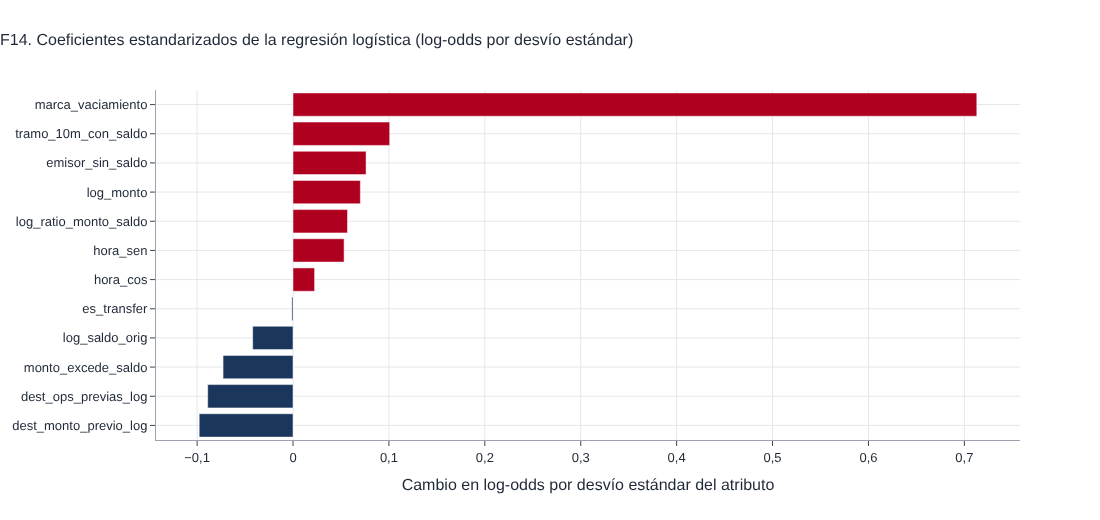

Figura guardada en outputs/figures/F14_explicabilidad.html y .png


,Atributo,Valor,Operaciones,Fraudes,Tasa de fraude (%),IC 95% (%)
0,marca_vaciamiento,1,"3,212","3,212",100.000,99.881 a 100.000
1,marca_vaciamiento,0,"1,726,554",67,0.004,0.003 a 0.005
2,tramo_10m_con_saldo,1,72,72,100.000,94.935 a 100.000
3,tramo_10m_con_saldo,0,"1,729,694","3,207",0.185,0.179 a 0.192
4,monto_excede_saldo,1,"1,552,033",29,0.002,0.001 a 0.003
5,monto_excede_saldo,0,"177,733","3,250",1.829,1.767 a 1.892
6,emisor_sin_saldo,1,"822,428",28,0.003,0.002 a 0.005
7,emisor_sin_saldo,0,"907,338","3,251",0.358,0.346 a 0.371
8,es_transfer,1,"325,909","1,630",0.500,0.476 a 0.525
9,es_transfer,0,"1,403,857","1,649",0.117,0.112 a 0.123


Retador (XGBoost), ganancia total relativa (suma de la mejora de pérdida aportada por cada atributo en todos los árboles): marca_vaciamiento 99,30%; tramo_10m_con_saldo 0,19%; log_ratio_monto_saldo 0,12%; log_monto 0,11%; log_saldo_orig 0,07%; dest_ops_previas_log 0,06%.


In [27]:
# 11.1 Coeficientes, tasas empíricas por atributo binario e importancia en el retador
fam = CAMPEON
if fam == "Regresión logística":
    lr = modelos[fam][-1]
    imp = pd.DataFrame({"Atributo": FEATURES, "Coeficiente estandarizado": lr.coef_[0]}).sort_values("Coeficiente estandarizado")
    titulo = "Coeficientes estandarizados de la regresión logística (log-odds por desvío estándar)"
else:
    est = modelos[fam][-1] if hasattr(modelos[fam], "steps") else modelos[fam]
    imp = pd.DataFrame({"Atributo": FEATURES, "Coeficiente estandarizado": getattr(est, "feature_importances_", np.zeros(len(FEATURES)))}).sort_values("Coeficiente estandarizado")
    titulo = f"Importancia de atributos de {fam}"
fig = go.Figure(go.Bar(x=imp["Coeficiente estandarizado"], y=imp["Atributo"], orientation="h",
                       marker_color=[COLOR_FRAUD if v > 0 else COLOR_LEGIT for v in imp["Coeficiente estandarizado"]]))
fig.update_layout(title=f"F14. {titulo}", height=500, margin=dict(t=90), xaxis_title="Cambio en log-odds por desvío estándar del atributo")
fig.show(); guardar_fig(fig, "F14_explicabilidad")

filas = []
for b in ["marca_vaciamiento", "tramo_10m_con_saldo", "monto_excede_saldo", "emisor_sin_saldo", "es_transfer"]:
    for val in (1, 0):
        msk = X_tr[b].to_numpy() == val
        k, n = int(y_tr[msk].sum()), int(msk.sum())
        lo, hi = wilson(k, n)
        filas.append({"Atributo": b, "Valor": val, "Operaciones": n, "Fraudes": k, "Tasa de fraude (%)": k / n * 100 if n else np.nan,
                      "IC 95% (%)": f"{lo*100:.3f} a {hi*100:.3f}"})
tasas = pd.DataFrame(filas)
tasas.to_csv(TAB_DIR / "tabla_tasas_por_atributo_binario.csv", index=False)
display(tasas.style.format({"Operaciones": "{:,}", "Fraudes": "{:,}", "Tasa de fraude (%)": "{:.3f}"}))
gi = pd.Series(modelos[RETADOR].get_booster().get_score(importance_type="total_gain") if RETADOR == "XGBoost" else {}, dtype=float)
if len(gi):
    gi = (gi / gi.sum() * 100).sort_values(ascending=False)
    print(f"Retador ({RETADOR}), ganancia total relativa (suma de la mejora de pérdida aportada por cada atributo en todos los árboles): " + "; ".join(f"{k} {f_num(v, 2)}%" for k, v in gi.head(6).items()) + ".")

## Sección 12. Latencia
Se mide el tiempo de puntuar una operación (llamada a la librería y cálculo de producción: producto escalar y sigmoide) y el de mantener el historial de 168 h en modo *streaming*, verificando que coincida con el cálculo fuera de línea. Se informa el orden de magnitud.

In [28]:
# 12.1 Latencia de inferencia por operación
from collections import defaultdict, deque
def cronometrar(f, n=2000):
    t0 = time.perf_counter_ns()
    for i in range(n):
        f(i)
    return (time.perf_counter_ns() - t0) / n / 1000

Xn = X_te.to_numpy()[:2000]
lat = {}
lat[f"{CAMPEON}: predict_proba de la librería, 1 operación"] = cronometrar(lambda i: modelos[CAMPEON].predict_proba(X_te.iloc[i:i+1]))
if CAMPEON == "Regresión logística":
    sc_, lr_ = modelos[CAMPEON][0], modelos[CAMPEON][-1]
    mu, sd, w, b0 = sc_.mean_, sc_.scale_, lr_.coef_[0], lr_.intercept_[0]
    lat[f"{CAMPEON}: producto escalar y sigmoide (NumPy), 1 operación"] = cronometrar(lambda i: 1 / (1 + np.exp(-(((Xn[i] - mu) / sd) @ w + b0))))
if RETADOR == "XGBoost":
    booster = modelos[RETADOR].get_booster()
    lat[f"{RETADOR}: inplace_predict, 1 operación"] = cronometrar(lambda i: booster.inplace_predict(Xn[i:i+1]), n=1000)
else:
    lat[f"{RETADOR}: predict_proba, 1 operación"] = cronometrar(lambda i: modelos[RETADOR].predict_proba(X_te.iloc[i:i+1]), n=300)
t0 = time.perf_counter(); modelos[CAMPEON].predict_proba(X_te.iloc[:100_000]); lat[f"{CAMPEON}: lote de 100.000, por operación"] = (time.perf_counter() - t0) / 1e5 * 1e6
t0 = time.perf_counter(); modelos[RETADOR].predict_proba(X_te.iloc[:100_000]); lat[f"{RETADOR}: lote de 100.000, por operación"] = (time.perf_counter() - t0) / 1e5 * 1e6

# 12.2 Historial en línea: réplica en streaming y verificación contra el cálculo fuera de línea
base = pd.read_parquet(DATA_PROC_DIR / "base_curada_paysim.parquet", columns=["step", "type", "nameDest", "amount"],
                       filters=[("step", ">=", 361 - VENTANA_H), ("step", "<=", 400)])
estado = defaultdict(deque)       # destino -> cola de (step, monto) recibidos
pendientes = []                   # operaciones de la hora en curso: se incorporan al estado al cerrar la hora
consultas, n_ops, t_total, step_actual = [], 0, 0.0, None
for st, tp, dst, mt in base.itertuples(index=False):
    t0 = time.perf_counter_ns()
    if st != step_actual:
        for d_, s_, m_ in pendientes:
            estado[d_].append((s_, m_))
        pendientes, step_actual = [], st
    if st >= 361 and tp in ("TRANSFER", "CASH_OUT"):
        q = estado[dst]
        while q and q[0][0] < st - VENTANA_H:
            q.popleft()
        consultas.append((st, dst, len(q), sum(m for _, m in q)))
    pendientes.append((dst, st, mt))
    t_total += time.perf_counter_ns() - t0; n_ops += 1
lat["Historial de 168 h en línea (Python puro), por operación procesada"] = t_total / n_ops / 1000
onl = pd.DataFrame(consultas, columns=["step", "nameDest", "ops_online", "monto_online"])
off = r.loc[(r["step"] >= 361) & (r["step"] <= 400), ["step", "nameDest", "ops_previas_168h", "monto_previo_168h"]].reset_index(drop=True)
assert len(onl) == len(off) and (onl["ops_online"].to_numpy() == off["ops_previas_168h"].to_numpy()).all() \
    and np.allclose(onl["monto_online"].to_numpy(), off["monto_previo_168h"].to_numpy())
latencias = pd.DataFrame({"Componente": list(lat), "Microsegundos por operación": list(lat.values())})
latencias.to_csv(TAB_DIR / "tabla_latencia_medida.csv", index=False)
display(latencias.style.format({"Microsegundos por operación": "{:,.2f}"}))
print(f"Verificación: el historial calculado en línea coincide exactamente con el atributo fuera de línea en {f_int(len(onl))} operaciones de riesgo.")
_prod = [v for k, v in lat.items() if "predict_proba" not in k]
print(f"Medido en: {platform.processor() or platform.machine()} ({platform.system()}). El cálculo que haría un servicio en producción (producto escalar, "
      f"XGBoost e historial) tarda como máximo {f_num(max(_prod), 1)} microsegundos por operación, muy por debajo de un milisegundo. La llamada a "
      f"predict_proba para una sola operación tarda {f_num(lat[[k for k in lat if 'predict_proba' in k][0]], 0)} microsegundos porque valida y convierte "
      "la entrada en cada llamada; no es el costo del modelo. En producción el costo dominante sería leer el estado del destino desde un almacenamiento "
      "en memoria compartido, que aquí no se mide.")
del base, estado

,Componente,Microsegundos por operación
0,"Regresión logística: predict_proba de la librería, 1 operación",729.73
1,"Regresión logística: producto escalar y sigmoide (NumPy), 1 operación",1.71
2,"XGBoost: inplace_predict, 1 operación",88.08
3,"Regresión logística: lote de 100.000, por operación",0.08
4,"XGBoost: lote de 100.000, por operación",1.25
5,"Historial de 168 h en línea (Python puro), por operación procesada",2.19


Verificación: el historial calculado en línea coincide exactamente con el atributo fuera de línea en 264.638 operaciones de riesgo.
Medido en: x86_64 (Linux). El cálculo que haría un servicio en producción (producto escalar, XGBoost e historial) tarda como máximo 88,1 microsegundos por operación, muy por debajo de un milisegundo. La llamada a predict_proba para una sola operación tarda 730 microsegundos porque valida y convierte la entrada en cada llamada; no es el costo del modelo. En producción el costo dominante sería leer el estado del destino desde un almacenamiento en memoria compartido, que aquí no se mide.


## Sección 13. Política en tres niveles
**Rojo** (puntaje ≥ umbral económico): retener y derivar a un analista. **Ámbar** (entre el borde inferior de la franja del 99,9% y el umbral rojo): verificación automática al titular. **Verde:** aprobar. Umbrales de validación; conteos en prueba.

In [29]:
# 13.1 Umbral ámbar en validación y política aplicada en prueba
s_c_te = s_te[CAMPEON]
U_AMB = FRANJA[CAMPEON][0]   # borde inferior de la franja con al menos el 99,9% del ahorro máximo
nivel = np.where(s_c_te >= UMBRAL[CAMPEON], "Rojo", np.where(s_c_te >= U_AMB, "Ámbar", "Verde"))
pol = pd.DataFrame({"nivel": nivel, "y": y_te}).groupby("nivel")["y"].agg(operaciones="size", fraudes="sum").reindex(["Verde", "Ámbar", "Rojo"]).fillna(0)
pol["legítimas"] = pol["operaciones"] - pol["fraudes"]
pol["% del tráfico"] = pol["operaciones"] / len(y_te) * 100
pol["por día"] = pol["operaciones"] / DIAS["Prueba"]
pol["% fraude dentro del nivel"] = np.where(pol["operaciones"] > 0, pol["fraudes"] / pol["operaciones"].replace(0, np.nan) * 100, np.nan)
pol["% de los fraudes"] = pol["fraudes"] / y_te.sum() * 100
pol.to_csv(TAB_DIR / "tabla_politica_tres_niveles.csv")
display(pol.style.format({"operaciones": "{:,.0f}", "fraudes": "{:,.0f}", "legítimas": "{:,.0f}", "% del tráfico": "{:.3f}",
                          "por día": "{:.1f}", "% fraude dentro del nivel": "{:.2f}", "% de los fraudes": "{:.2f}"}))
print(f"Umbrales (puntaje del campeón): ámbar desde {f_num(U_AMB, 3)}, rojo desde {f_num(UMBRAL[CAMPEON], 3)}.")
print(f"Rojo: {f_num(pol.loc['Rojo', 'por día'], 1)} casos por día, {f_num(pol.loc['Rojo', '% fraude dentro del nivel'], 2)}% fraude; "
      f"ámbar: {f_num(pol.loc['Ámbar', 'por día'], 1)} verificaciones por día; verde: {f_num(pol.loc['Verde', '% del tráfico'], 2)}% del tráfico "
      f"con {int(pol.loc['Verde', 'fraudes'])} fraudes no detectados.")
print("Monitoreo recomendado: alertas rojas por día, proporción de rojas confirmadas como fraude y proporción de fraudes confirmados que no "
      "siguen la firma de vaciamiento; un aumento sostenido de esta última es la señal temprana del cambio de táctica de la sección 10.")

,operaciones,fraudes,legítimas,% del tráfico,por día,% fraude dentro del nivel,% de los fraudes
nivel,,,,,,,
Verde,"501,174",3,"501,171",99.142,31323.4,0.00,0.07
Ámbar,144,0,144,0.028,9.0,0.00,0.00
Rojo,"4,193","4,193",0,0.829,262.1,100.00,99.93


Umbrales (puntaje del campeón): ámbar desde -9,148, rojo desde -1,456.
Rojo: 262,1 casos por día, 100,00% fraude; ámbar: 9,0 verificaciones por día; verde: 99,14% del tráfico con 3 fraudes no detectados.
Monitoreo recomendado: alertas rojas por día, proporción de rojas confirmadas como fraude y proporción de fraudes confirmados que no siguen la firma de vaciamiento; un aumento sostenido de esta última es la señal temprana del cambio de táctica de la sección 10.


## Sección 14. Ética, equidad y normativa
Dos riesgos concretos: **retener clientes honestos** y el **sesgo contra cuentas sin historial**, que suelen ser usuarios nuevos en el sistema financiero. La celda siguiente mide los falsos positivos por segmento.

In [30]:
# 14.1 Tasa de falsos positivos del campeón por segmento (prueba)
seg = pd.DataFrame({"y": y_te, "a": a_c,
                    "Destino": np.where(X_te["dest_ops_previas_log"].to_numpy() > 0, "con historial 168 h", "sin historial 168 h"),
                    "Origen": np.where(X_te["emisor_sin_saldo"].to_numpy() == 1, "saldo 0", "con saldo"),
                    "Tipo": np.where(X_te["es_transfer"].to_numpy() == 1, "TRANSFER", "CASH_OUT")})
filas = []
for dim in ("Destino", "Origen", "Tipo"):
    for val, g in seg.groupby(dim):
        leg = g[g["y"] == 0]; frd = g[g["y"] == 1]
        filas.append({"Dimensión": dim, "Segmento": val, "Legítimas": len(leg), "Falsos positivos": int(leg["a"].sum()),
                      "FP por millón de legítimas": leg["a"].mean() * 1e6 if len(leg) else np.nan,
                      "Límite sup. IC 95% (por millón)": wilson(int(leg["a"].sum()), len(leg))[1] * 1e6 if len(leg) else np.nan,
                      "Fraudes": len(frd), "Sensibilidad (%)": frd["a"].mean() * 100 if len(frd) else np.nan})
eq = pd.DataFrame(filas)
eq.to_csv(TAB_DIR / "tabla_equidad_segmentos.csv", index=False)
display(eq.style.format({"Legítimas": "{:,}", "Falsos positivos": "{:,}", "FP por millón de legítimas": "{:,.1f}",
                        "Límite sup. IC 95% (por millón)": "{:,.1f}", "Fraudes": "{:,}", "Sensibilidad (%)": "{:.2f}"}))
d = eq[eq["Dimensión"] == "Destino"].set_index("Segmento")["FP por millón de legítimas"]
lim = eq[eq["Dimensión"] == "Destino"].set_index("Segmento")["Límite sup. IC 95% (por millón)"]
sens_o = eq[eq["Dimensión"] == "Origen"].set_index("Segmento")
print(f"Falsos positivos por millón de legítimas: {f_num(d['sin historial 168 h'], 1)} hacia destinos sin historial y {f_num(d['con historial 168 h'], 1)} "
      f"hacia destinos con historial (con 0 eventos, el límite superior de Wilson es {f_num(lim['sin historial 168 h'], 1)} y "
      f"{f_num(lim['con historial 168 h'], 1)} por millón, respectivamente). En este período no se observa sesgo en contra de las cuentas sin historial.")
so, sc_ = sens_o.loc["saldo 0", "Sensibilidad (%)"], sens_o.loc["con saldo", "Sensibilidad (%)"]
print(f"Sensibilidad por perfil del origen: {f_num(so, 1)}% en cuentas con saldo 0 ({int(sens_o.loc['saldo 0', 'Fraudes'])} fraudes) y {f_num(sc_, 1)}% en el resto. "
      + ("Las víctimas con saldo 0 quedan menos protegidas." if so < sc_ - 1 else "Con tan pocos casos en el primer grupo, la comparación es solo indicativa."))

,Dimensión,Segmento,Legítimas,Falsos positivos,FP por millón de legítimas,Límite sup. IC 95% (por millón),Fraudes,Sensibilidad (%)
0,Destino,con historial 168 h,"365,481",0,0.0,10.5,883,100.00
1,Destino,sin historial 168 h,"135,834",0,0.0,28.3,"3,313",99.91
2,Origen,con saldo,"272,647",0,0.0,14.1,"4,183",99.93
3,Origen,saldo 0,"228,668",0,0.0,16.8,13,100.00
4,Tipo,CASH_OUT,"400,860",0,0.0,9.6,"2,098",100.00
5,Tipo,TRANSFER,"100,455",0,0.0,38.2,"2,098",99.86


Falsos positivos por millón de legítimas: 0,0 hacia destinos sin historial y 0,0 hacia destinos con historial (con 0 eventos, el límite superior de Wilson es 28,3 y 10,5 por millón, respectivamente). En este período no se observa sesgo en contra de las cuentas sin historial.
Sensibilidad por perfil del origen: 100,0% en cuentas con saldo 0 (13 fraudes) y 99,9% en el resto. Con tan pocos casos en el primer grupo, la comparación es solo indicativa.


**Salvaguardas.** (1) Ninguna retención definitiva sin revisión humana, con explicación al cliente basada en los factores del modelo. (2) Publicar los falsos positivos por segmento en el tablero de monitoreo. (3) Usar el historial solo como atenuante. (4) Dejar registro auditable de cada decisión: las billeteras se rigen por las normas del BCRA sobre el Sistema Nacional de Pagos y los sujetos obligados reportan operaciones sospechosas a la UIF (Ley 25.246). La adecuación normativa concreta requiere asesoramiento especializado.

In [31]:
# 14.2 Serialización de los modelos y de la metadata necesaria para reproducir la decisión
SLUG = {"Regresión logística": "logistica", "LDA": "lda", "QDA": "qda", "Árbol de decisión (CART)": "cart", "Random Forest": "random_forest", "XGBoost": "xgboost"}
art = {"campeon": (CAMPEON, f"campeon_{SLUG[CAMPEON]}.joblib"), "retador": (RETADOR, f"retador_{SLUG[RETADOR]}.joblib")}
for rol, (fam, archivo) in art.items():
    joblib.dump(modelos[fam], MOD_DIR / archivo)
m_cent, u_cent, cols_cent = abl_modelos[(CAMPEON, "Sin firmas exactas")]
joblib.dump(m_cent, MOD_DIR / "centinela_sin_firmas.joblib")
meta = {"atributos": FEATURES, "semilla": SEED, "particion": {"entrenamiento": "steps 1-288", "validacion": "steps 289-360", "prueba": "steps 361-743"},
        "campeon": {"familia": CAMPEON, "archivo": art["campeon"][1], "hiperparametros": mejor.set_index("Familia").loc[CAMPEON, "_hp"],
                    "umbral_rojo_puntaje": float(UMBRAL[CAMPEON]), "umbral_ambar_puntaje": float(U_AMB), "umbral_borde_superior_puntaje": float(FRANJA[CAMPEON][1]),
                    "criterio_umbral": "punto medio de la franja con al menos el 99,9% del ahorro máximo de validación; cupo verificado día por día", "escala_puntaje": "log-odds" if CAMPEON != "Random Forest" else "probabilidad"},
        "retador": {"familia": RETADOR, "archivo": art["retador"][1], "hiperparametros": mejor.set_index("Familia").loc[RETADOR, "_hp"],
                    "umbral_puntaje": float(UMBRAL[RETADOR])},
        "retador_entrenado_con_ataques": {"familia": RETADOR, "archivo": f"retador_{RETADOR.lower().replace(' ', '_')}_entrenado_con_ataques.joblib",
                    "descripcion": "mismos hiperparámetros, entrenamiento aumentado con retiros parciales sintéticos entre 50% y 99% del saldo (sección 10.3)",
                    "umbral_puntaje": float(u_ata[RETADOR])},
        "centinela": {"descripcion": f"{CAMPEON} sin firmas exactas (sección 10)", "archivo": "centinela_sin_firmas.joblib",
                      "atributos": cols_cent, "umbral_puntaje": float(u_cent)},
        "costos_supuestos": {"revision": C_REV, "friccion": C_FRIC, "capacidad_diaria": CAP_DIA},
        "versiones": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "xgboost": xgb.__version__, "pandas": pd.__version__}}
(MOD_DIR / "metadata_modelos.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
for rol, (fam, archivo) in art.items():
    print(f"{rol.capitalize()}: {fam} -> {ruta_rel(MOD_DIR / archivo)} ({f_num((MOD_DIR / archivo).stat().st_size / 1024, 1)} KB)")
print(f"Centinela: {CAMPEON} sin firmas exactas -> {ruta_rel(MOD_DIR / 'centinela_sin_firmas.joblib')}")
print(f"Metadata: {ruta_rel(MOD_DIR / 'metadata_modelos.json')}")

Campeon: Regresión logística -> outputs/models/campeon_logistica.joblib (2,1 KB)
Retador: XGBoost -> outputs/models/retador_xgboost.joblib (313,5 KB)
Centinela: Regresión logística sin firmas exactas -> outputs/models/centinela_sin_firmas.joblib
Metadata: outputs/models/metadata_modelos.json


## Sección 15. Conclusiones y recomendación

Cada cifra remite a la celda que la calcula.

**1. Seis modelos empatan y decide una regla declarada.** En la validación cruzada temporal la PR-AUC media va de 0,99783 a 0,99805, y la diferencia entre familias (0,00021) es menor que un error estándar (0,00105) (celdas 5.2 y 5.3). La regla de un error estándar elige la **regresión logística** (C = 0,01, sin reponderar) como campeón y **XGBoost** como retador (celda 6.1).

**2. Sin sobreajuste; la calibración se mide donde hay datos.** Ningún modelo supera el 5% de brecha entre entrenamiento y validación (celda 6.2) ni entre entrenamiento y prueba (celda 9.5). El Brier de la logística en validación es 4,03 × 10⁻⁹ frente a 1,38 × 10⁻³ de referencia (celda 7.1): con clases casi separadas, ese valor refleja la separación más que una calibración fina de las probabilidades intermedias, que casi no se observan. En prueba es 5,94 × 10⁻⁶ frente a 8,23 × 10⁻³ (celda 9.2).

**3. El umbral se calcula y su criterio se declara.** En validación, los umbrales entre −9,148 y 6,237 en log-odds alcanzan al menos el 99,9% del ahorro máximo sin superar el cupo en ningún día, y se adopta su punto medio, −1,456 (celda 8.1). Entre −8,954 y 6,237 todos generan las mismas alertas, así que la validación no los ordena: el centro es el que deja más margen frente a lo no observado. Ese criterio se adoptó después de observar la prueba. Con el borde superior, que era la regla original, pasan 12 fraudes en lugar de 3 y el ahorro es 98,42% en lugar de 99,64%: 98,42% es la cifra conservadora. Con datos anteriores a la prueba las dos reglas eran casi equivalentes (2 y 4 fraudes no detenidos sobre 1.580). Con costos multiplicados hasta por 20 y capacidad entre 500 y 2.000 alertas, el ahorro queda entre 99,26% y 99,69%. Con 50 revisiones diarias el umbral sube a 7,187: en prueba se atienden 800 de 1.047 candidatas y el ahorro baja a 31,79% (50,34% si se atendieran todas) (celda 8.2).

**4. Resultado en prueba (días 16 a 31), con el punto medio.** El campeón detiene 4.193 de 4.196 fraudes (99,93%; IC 95% 99,79% a 99,98%) sin falsos positivos entre 501.315 legítimas y con 262,1 alertas diarias (320 en el día más cargado). Ahorra 6.549,6 millones de u.m., el 99,64% del monto (IC 95% 99,29% a 99,90%), frente al 1,08% de la regla vigente y el 71,23% de la regla de monto alto, que con el cupo de 1.000 revisiones diarias atiende 5.373 de 11.086 candidatas (859 fraudes y 4.514 falsos positivos); sin cupo ahorraría 75,95% y retendría a 10.149 clientes honestos (celdas 9.1 y 9.2). Los 3 fraudes no detectados los marca la regla vigente (celda 9.4).

**5. Lectura honesta.** Las firmas se identificaron al explorar el mes completo y ya estaban presentes en los días 1 a 12 (celda 3.2). La regla de firmas logra el mismo resultado que el campeón (celda 9.1): en PaySim la diferencia la hace entender al atacante, no el algoritmo. El modelo aporta un puntaje que permite mover el umbral, graduar la respuesta y monitorear.

**6. La detección depende de una igualdad exacta.** Con cualquier retiro parcial, incluso dejando un centavo, el campeón y la regla de firmas detienen el 0,3%, y el XGBoost original entre 0,3% y 1,1% (1,0% ante el retiro del 90%) (celda 10.3). Operar de día o hacia un destino con historial no los afecta; ante el robo fraccionado alertan tarde y protegen 50,0%, 33,3% y 20,0% del monto con 2, 3 y 5 partes.

**7. Entrenar con ataques ayuda, dentro de un límite.** XGBoost reentrenado con retiros sintéticos del 50% al 99% detiene 86,9% ante el retiro del 90% y ahorra 98,45% en ese escenario (99,63% en condiciones normales), con 108,8 clientes honestos retenidos por día; fuera de ese rango cae a 7,6% y 1,0% (retiros del 30% y del 10%). El centinela sin firmas conserva 41,5% ante el retiro del 10%. El 10,0% de las legítimas pide menos que el saldo: un robo chico no se distingue de ellas con estos atributos (celda 10.3).

**8. La madrugada.** De las 2.226 legítimas reales de prueba entre la 1 y las 5 h, el campeón no retiene ninguna y envía 20 a verificación; aun si todas las legítimas operaran a las 3 h, no retendría a ninguna. Los modelos de control detectan de madrugada los retiros del 90%, pero dependen de la hora: con toda la operación legítima a las 3 h marcarían 1.455,3 y 2.123,8 operaciones por día, por lo que sus alertas deben leerse por franja horaria (celda 10.3).

**9. Operación y equidad.** Rojo: 262,1 casos diarios, todos fraude; ámbar: 9,0 verificaciones diarias; verde: 99,14% del tráfico (celda 13.1). Puntuar una operación toma microsegundos (celda 12.1). No hay falsos positivos en ningún segmento; la cota de Wilson para destinos sin historial es 28,3 por millón (celda 14.1).

**Recomendación.** Desplegar la logística con el umbral económico y la política de tres niveles, mantener la regla vigente como red y correr en paralelo, sin retener a nadie, el XGBoost entrenado con ataques y el centinela. La logística sigue como campeón porque se eligió con el protocolo sobre los datos originales; ascender al XGBoost por ataques diseñados por el equipo sería elegir con la prueba.

**Limitaciones y próximos pasos.** Datos simulados, costos supuestos, ataques diseñados por el equipo, pliegues de tres días y un criterio de umbral adoptado tras observar la prueba. Próximos pasos: sumar señales de dispositivo y velocidad, medir cuánto tardan los modelos de control en detectar un cambio y validar con datos reales.

**Referencias.** Breiman, Friedman, Olshen y Stone (1984), *Classification and Regression Trees*. · Brown, Cai y DasGupta (2001), Interval estimation for a binomial proportion, *Statistical Science* 16(2). · Chen y Guestrin (2016), XGBoost: A scalable tree boosting system, *KDD 2016*. · Efron y Tibshirani (1993), *An Introduction to the Bootstrap*. · Elkan (2001), The foundations of cost-sensitive learning, *IJCAI 2001*. · Hastie, Tibshirani y Friedman (2009), *The Elements of Statistical Learning* (2.ª ed.). · Hyndman y Athanasopoulos (2021), *Forecasting: Principles and Practice* (3.ª ed.). · Kaufman, Rosset, Perlich y Stitelman (2012), Leakage in data mining, *ACM TKDD* 6(4). · Künsch (1989), The jackknife and the bootstrap for general stationary observations, *The Annals of Statistics* 17(3). · Saito y Rehmsmeier (2015), The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets, *PLOS ONE* 10(3).